# Taller: Reducción de dimensionalidad, análisis espectral y transformadas integrales
**Asignatura:** Métodos de Machine Learning en Ciencias e Ingenierías (106023C) · **Semestre:** 2026A
**Temas:** SVD, PCA, Fourier (FFT) y Wavelets (DWT)
**Integrantes:** Juan Esteban Martinez Herrera · Juan David Cuartas  
**Instituciones:** Universidad del Quindío · Universidad del Valle

| Ejercicio | Contenido | Datos |
|---|---|---|
| 1 | Compresión y reconstrucción 1D: FFT vs. DWT (en parejas) | ECG real, MIT-BIH registro 208 (fragmento de 5 min incluido en SciPy) |
| 2 | Aislamiento de fuentes puntuales 2D: 2D-DWT vs. 2D-FFT | Imagen proporcionada: `epico.tif` (ver la celda de carga) |
| 3 | Mapa mental sistémico (5 nodos) | — |

**Cómo leer este cuaderno.** Todo el código se ejecuta de principio a fin sin intervención (no hay aleatoriedad). Las cifras citadas en las discusiones salen de las celdas de código anteriores; los resultados completos se guardan en `resultados.json`.

**Datos.** (i) el ECG es el registro 208 de la MIT-BIH tal como lo empaqueta SciPy (360 Hz, 5 min); para usar la descarga oficial de PhysioNet se pone `ECG_FUENTE = "physionet"`; (ii) en el Ejercicio 2 se usa la imagen indicada en `RUTA_IMAGEN` (la celda de carga describe la lectura y el preprocesado) Antes de recortar se promedió la imagen en bloques de 3×3 píxeles (`REDUCIR`), para que las estrellas tengan un ancho comparable a la escala del filtro del enunciado.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.patches import Rectangle
import pywt
from scipy.fft import fft, ifft, fft2, ifft2, fftshift, ifftshift, fftfreq
from scipy.signal import find_peaks
from scipy import ndimage as ndi
from skimage.color import rgb2gray
from skimage.feature import peak_local_max

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
DATA, FIG = Path("data"), Path("figuras"); FIG.mkdir(exist_ok=True)
RES = {}                                    # cifras clave del taller → resultados.json
print("NumPy", np.__version__, "| PyWavelets", pywt.__version__)

NumPy 2.4.2 | PyWavelets 1.8.0


---
# Ejercicio 1 · Compresión y reconstrucción 1D: FFT vs. DWT
*(en parejas: Integrante 1 → Partes 1 y 2 · Integrante 2 → Parte 3)*

**Señal elegida.** Electrocardiograma real de la *MIT-BIH Arrhythmia Database* (registro 208, 360 Hz). Es una señal **no estacionaria** por construcción: complejos QRS muy estrechos (transitorios de ~80 ms) sobre ondas P/T lentas y deriva de línea base, con latidos ectópicos intercalados.

**Marco de trabajo.**

* **DFT/FFT:** $\hat x_F[k]=\sum_{n=0}^{N-1}x[n]\,e^{-i2\pi kn/N}$, con Parseval $\;\sum_n|x[n]|^2=\tfrac1N\sum_k|\hat x_F[k]|^2$.
* **DWT** multirresolución con `db4` y $L=5$: $x[n]=\sum_k A_5[k]\phi_{5,k}[n]+\sum_{j=1}^{5}\sum_k D_j[k]\psi_{j,k}[n]$. Se usa `mode="periodization"`, que la hace una transformada **ortogonal exacta** de $N$ coeficientes (con Parseval, igual que la FFT normalizada).
* **Criterio de compresión (idéntico para ambos métodos):** conservar los $M$ coeficientes de mayor energía $|c|^2$ hasta acumular el **95 %** de la energía total y fijar el resto a cero.
* **Convención de conteo en la FFT.** Como $x$ es real, $\hat x_F[N-k]=\overline{\hat x_F[k]}$; los coeficientes se conservan **por pares** $(k,N-k)$ para que la reconstrucción sea real. Cada par equivale a un número complejo (2 reales), de modo que $M_F$ cuenta, en la práctica, tantos números reales como $M_W$ en la DWT y la comparación es justa.
* **Métricas:** $CR=N/M$ y $MSE=\frac1N\sum_n (x[n]-x_{rec}[n])^2$.

> **Observación previa (Parseval).** Como ambas bases son ortonormales y ambos métodos descartan ≈5 % de la energía, **el MSE será prácticamente el mismo por construcción**. La diferencia entre métodos aparece en **cuántos coeficientes (M) hacen falta** y en **dónde cae el error**.

MIT-BIH 208 · fragmento de 5 min (copia de SciPy incluida en data/)
Señal disponible: 108000 muestras (5.0 min a 360 Hz)
Segmento de trabajo: N = 8192 muestras (22.76 s) | media = -0.183 mV | σ = 0.541 mV


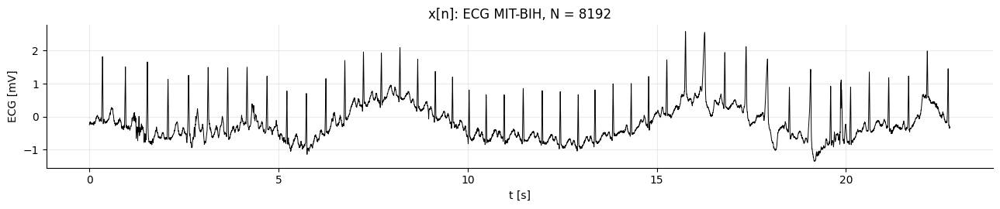

In [2]:
# ── Datos: ECG real, MIT-BIH Arrhythmia Database (registro 208, canal MLII, 360 Hz) ──
ECG_FUENTE = "local"      # "local": data/ecg_mitbih208.npy (copia de SciPy) · "physionet": descarga oficial con wfdb (pip install wfdb) · "scipy"
FS = 360.0                # Hz

def cargar_ecg(fuente):
    if fuente == "physionet":
        import wfdb                                               # datos públicos: no requiere cuenta ni credenciales
        reg = wfdb.rdrecord("208", pn_dir="mitdb")               # registro oficial completo (30 min, 650 000 muestras)
        return reg.p_signal[:, 0].astype(float), float(reg.fs), "PhysioNet · MIT-BIH 208 (descarga oficial con wfdb)"
    ruta_ecg = DATA / "ecg_mitbih208.npy"
    if fuente == "local" and ruta_ecg.exists():
        return np.load(ruta_ecg), 360.0, "MIT-BIH 208 · fragmento de 5 min (copia de SciPy incluida en data/)"
    from scipy import datasets                                    # misma señal que empaqueta SciPy (necesita red y pooch)
    return datasets.electrocardiogram(), 360.0, "MIT-BIH 208 · fragmento de 5 min (scipy.datasets)"

ecg, FS, ORIGEN_ECG = cargar_ecg(ECG_FUENTE)
RES["ej1_fuente"] = ORIGEN_ECG

N = 8192                                     # N ≥ 4096; potencia de 2 (≈ 22.8 s)
x = ecg[:N].astype(float)
t = np.arange(N) / FS
print(f"{ORIGEN_ECG}\nSeñal disponible: {len(ecg)} muestras ({len(ecg)/FS/60:.1f} min a {FS:.0f} Hz)")
print(f"Segmento de trabajo: N = {N} muestras ({N/FS:.2f} s) | media = {x.mean():+.3f} mV | σ = {x.std():.3f} mV")

fig, ax = plt.subplots(figsize=(13, 2.8))
ax.plot(t, x, "k", lw=.7)
ax.set(xlabel="t [s]", ylabel="ECG [mV]", title=f"x[n]: ECG MIT-BIH, N = {N}")
ax.grid(alpha=.25); plt.tight_layout(); plt.show()

In [3]:
# ── Utilidades de compresión (mismo criterio de energía para FFT y DWT) ──
def m_para_energia(E_ordenada, frac):
    """Menor M tal que los M coeficientes de mayor energía acumulan >= frac de la energía total."""
    acum = np.cumsum(E_ordenada) / E_ordenada.sum()
    return int(np.searchsorted(acum, frac) + 1)

def comprimir_fft(x, frac=None, M=None):
    """FFT -> conservar los M coeficientes de mayor |X_k|^2 (o los necesarios para 'frac' de la energía)."""
    N = len(x)
    X = fft(x)                               # X[k] = Σ x[n] e^{-i2πkn/N}
    E = np.abs(X)**2
    orden = np.argsort(E)[::-1]
    if M is None:
        M = m_para_energia(E[orden], frac)
    keep = np.zeros(N, bool); keep[orden[:M]] = True
    idx = np.flatnonzero(keep); keep[(-idx) % N] = True     # señal real: se conservan k y N-k juntos
    return np.where(keep, X, 0), keep

def comprimir_dwt(x, frac=None, M=None, wavelet="db4", nivel=5):
    """DWT multirresolución -> umbral global por energía. Devuelve (coefs_comprimidos, arr, arr_comprimido, slices)."""
    coefs = pywt.wavedec(x, wavelet, level=nivel, mode="periodization")      # [A5, D5, D4, D3, D2, D1]
    arr, sl = pywt.coeffs_to_array(coefs)
    E = arr**2
    orden = np.argsort(E)[::-1]
    if M is None:
        M = m_para_energia(E[orden], frac)
    arr_c = np.zeros_like(arr); arr_c[orden[:M]] = arr[orden[:M]]
    return pywt.array_to_coeffs(arr_c, sl, output_format="wavedec"), arr, arr_c, sl

### Parte 1 · Integrante 1 — FFT: número mínimo de coeficientes para el 95 % de la energía

In [4]:
X = fft(x)                                   # x̂_F[k]
E_total = np.sum(x**2)
print(f"Parseval:  Σ|x[n]|² = {E_total:.4f}   |   (1/N) Σ|x̂_F[k]|² = {np.sum(np.abs(X)**2)/N:.4f}")

Xc, keep_F = comprimir_fft(x, frac=0.95)     # vector comprimido  x̃_F  (N-M_F coeficientes puestos a cero)
M_F = int(keep_F.sum())
E_ret_F = np.sum(np.abs(Xc)**2) / N / E_total
f_Hz = fftfreq(N, 1/FS)
f_max_F = np.abs(f_Hz[keep_F]).max()
dc_pct = 100 * N * x.mean()**2 / E_total
print(f"M_F = {M_F} de {N} coeficientes ({100*M_F/N:.2f} %)  →  energía retenida = {100*E_ret_F:.2f} %")
print(f"Frecuencia máxima conservada: {f_max_F:.1f} Hz   |   la componente DC aporta el {dc_pct:.1f} % de la energía total")
RES.update(ej1_M_F=M_F, ej1_Eret_F=100*E_ret_F, ej1_fmax_F=float(f_max_F), ej1_dc_pct=float(dc_pct))

Parseval:  Σ|x[n]|² = 2672.1471   |   (1/N) Σ|x̂_F[k]|² = 2672.1471
M_F = 577 de 8192 coeficientes (7.04 %)  →  energía retenida = 95.01 %
Frecuencia máxima conservada: 29.2 Hz   |   la componente DC aporta el 10.3 % de la energía total


### Parte 2 · Integrante 1 — DWT multirresolución (db4, $L=5$)

In [5]:
WAV, NIVEL = "db4", 5
coefs_c, arr, arr_c, slices = comprimir_dwt(x, frac=0.95, wavelet=WAV, nivel=NIVEL)
M_W = int(np.count_nonzero(arr_c))
E_ret_W = np.sum(arr_c**2) / np.sum(arr**2)
print(f"Parseval DWT:  Σ|x[n]|² = {E_total:.4f}   |   Σ coef² = {np.sum(arr**2):.4f}")
print(f"M_W = {M_W} de {N} coeficientes ({100*M_W/N:.2f} %)  →  energía retenida = {100*E_ret_W:.2f} %")

# Anatomía de la descomposición: banda de frecuencia, energía y coeficientes retenidos por subbanda
nombres = ["A5"] + [f"D{j}" for j in range(NIVEL, 0, -1)]
coefs_full = pywt.wavedec(x, WAV, level=NIVEL, mode="periodization")
filas_sb = []
for nom, c, cq in zip(nombres, coefs_full, coefs_c):
    j = NIVEL if nom == "A5" else int(nom[1])
    lo, hi = (0.0, FS/2**(NIVEL+1)) if nom == "A5" else (FS/2**(j+1), FS/2**j)
    filas_sb.append({"subbanda": nom, "banda [Hz]": f"{lo:.1f}–{hi:.1f}", "n.º coef.": len(c),
                  "energía [%]": 100*np.sum(c**2)/E_total, "retenidos": int(np.count_nonzero(cq))})
tabla_dwt = pd.DataFrame(filas_sb)
display(tabla_dwt)
RES.update(ej1_M_W=M_W, ej1_Eret_W=100*E_ret_W,
           ej1_niveles={r["subbanda"]: dict(energia=float(r["energía [%]"]), retenidos=int(r["retenidos"])) for r in filas_sb})

# "Entrega" de los vectores comprimidos al Integrante 2
np.savez(DATA / "ej1_comprimidos.npz", Xc=Xc, arr_c=arr_c)

Parseval DWT:  Σ|x[n]|² = 2672.1471   |   Σ coef² = 2672.1471
M_W = 334 de 8192 coeficientes (4.08 %)  →  energía retenida = 95.03 %


,subbanda,banda [Hz],n.º coef.,energía [%],retenidos
0,A5,0.0–5.6,256,80.228951,198
1,D5,5.6–11.2,256,8.467666,52
2,D4,11.2–22.5,512,7.982648,50
3,D3,22.5–45.0,1024,2.968675,34
4,D2,45.0–90.0,2048,0.333041,0
5,D1,90.0–180.0,4096,0.019019,0


### Parte 3 · Integrante 2 — Reconstrucción, residuos, CR y MSE

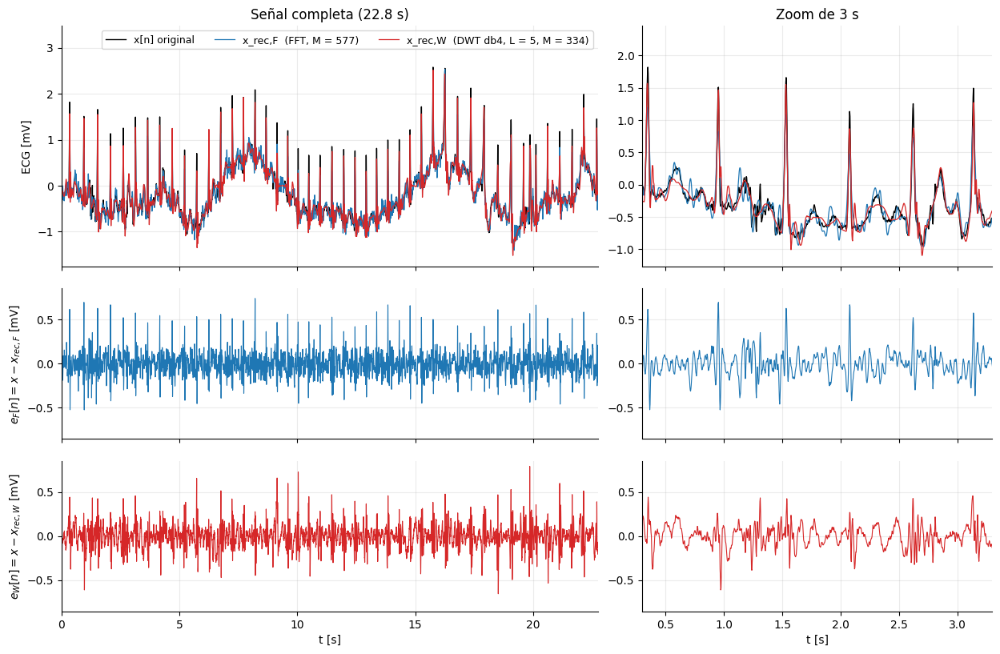

In [6]:
# ── Integrante 2: recibe los vectores comprimidos y aplica las transformadas inversas ──
datos = np.load(DATA / "ej1_comprimidos.npz")
x_F = np.real(ifft(datos["Xc"]))                                                          # iFFT
x_W = pywt.waverec(pywt.array_to_coeffs(datos["arr_c"], slices, output_format="wavedec"),
                   WAV, mode="periodization")                                              # iDWT
e_F, e_W = x - x_F, x - x_W                                                                # residuos e[n] = x[n] − x_rec[n]

# Señal original, reconstrucciones y residuos en una misma figura (columna izq.: completa · derecha: zoom de 3 s)
fig = plt.figure(figsize=(15, 9.5))
gs = gridspec.GridSpec(3, 2, height_ratios=[1.6, 1, 1], width_ratios=[2.3, 1.5], hspace=.12, wspace=.1)
lim_e = 1.08 * max(np.abs(e_F).max(), np.abs(e_W).max())
for col, (xl, tit) in enumerate([((0, N/FS), f"Señal completa ({N/FS:.1f} s)"), ((0.3, 3.3), "Zoom de 3 s")]):
    sel = (t >= xl[0]) & (t <= xl[1])
    a0 = fig.add_subplot(gs[0, col]); a1 = fig.add_subplot(gs[1, col], sharex=a0); a2 = fig.add_subplot(gs[2, col], sharex=a0)
    a0.plot(t, x, "k", lw=1.0, label="x[n] original")
    a0.plot(t, x_F, color="C0", lw=.9, label=f"x_rec,F  (FFT, M = {M_F})")
    a0.plot(t, x_W, color="C3", lw=.9, label=f"x_rec,W  (DWT {WAV}, L = {NIVEL}, M = {M_W})")
    a1.plot(t, e_F, color="C0", lw=.8); a2.plot(t, e_W, color="C3", lw=.8)
    ymin = min(x[sel].min(), x_F[sel].min(), x_W[sel].min()); ymax = max(x[sel].max(), x_F[sel].max(), x_W[sel].max())
    a0.set_xlim(*xl); a0.set_ylim(ymin - .06*(ymax-ymin), ymax + .22*(ymax-ymin))
    for a in (a1, a2): a.set_ylim(-lim_e, lim_e)
    a0.set_title(tit); a2.set_xlabel("t [s]")
    plt.setp(a0.get_xticklabels(), visible=False); plt.setp(a1.get_xticklabels(), visible=False)
    if col == 0:
        a0.legend(loc="upper right", ncol=3, fontsize=9); a0.set_ylabel("ECG [mV]")
        a1.set_ylabel(r"$e_F[n]=x-x_{rec,F}$ [mV]"); a2.set_ylabel(r"$e_W[n]=x-x_{rec,W}$ [mV]")
    for a in (a0, a1, a2): a.grid(alpha=.25)
plt.savefig(FIG / "ej1_reconstruccion.png", bbox_inches="tight"); plt.show()

In [7]:
def metricas_1d(x, xr, M, nombre):
    e = x - xr; mse = np.mean(e**2)
    return {"método": nombre, "M": M, "CR = N/M": len(x)/M, "MSE [mV²]": mse,
            "RMSE [mV]": np.sqrt(mse), "SNR [dB]": 10*np.log10(np.sum(x**2)/np.sum(e**2))}

tabla_1d = pd.DataFrame([metricas_1d(x, x_F, M_F, "FFT (95 % energía)"),
                         metricas_1d(x, x_W, M_W, f"DWT {WAV} L={NIVEL} (95 % energía)")]).set_index("método")
display(tabla_1d)

# Comprobación por Parseval: MSE = (energía descartada)/N  (ambas transformadas son ortonormales)
mse_teo_F = np.sum(np.abs(X[~keep_F])**2) / N**2
mse_teo_W = np.sum(arr[arr_c == 0]**2) / N
print(f"MSE medido vs. predicho por Parseval →  FFT: {tabla_1d.iloc[0, 2]:.6f} vs {mse_teo_F:.6f}   |   DWT: {tabla_1d.iloc[1, 2]:.6f} vs {mse_teo_W:.6f}")
RES.update(ej1_CR_F=N/M_F, ej1_CR_W=N/M_W, ej1_MSE_F=float(tabla_1d.iloc[0, 2]), ej1_MSE_W=float(tabla_1d.iloc[1, 2]),
           ej1_SNR_F=float(tabla_1d.iloc[0, 4]), ej1_SNR_W=float(tabla_1d.iloc[1, 4]))

,M,CR = N/M,MSE [mV²],RMSE [mV],SNR [dB]
método,,,,,
FFT (95 % energía),577,14.197574,0.016288,0.127624,13.016075
DWT db4 L=5 (95 % energía),334,24.526946,0.016206,0.127303,13.037963


MSE medido vs. predicho por Parseval →  FFT: 0.016288 vs 0.016288   |   DWT: 0.016206 vs 0.016206


#### ¿Dónde cae el error? Fidelidad en los complejos QRS (transitorios)
Para valorar la preservación de **eventos transitorios** se detectan los picos R y se mide, en ventanas de ±60 ms alrededor de cada uno: (i) cuánto de la **amplitud del pico R** conserva cada método, y (ii) el **RMS del error** dentro y fuera de esas ventanas.

In [8]:
def picos_R(x, umbral=0.8, sep=0.25):
    pk, _ = find_peaks(np.abs(x - np.median(x)), height=umbral, distance=int(sep*FS))
    return pk

def fidelidad_transitorios(x, xF, xW, semi=0.06):
    w = int(semi * FS); pk = picos_R(x); pk = pk[(pk > w) & (pk < len(x) - w)]
    med = np.median(x); mask = np.zeros(len(x), bool)
    for p in pk: mask[p-w:p+w+1] = True
    out = {"n_picos": len(pk), "frac_QRS": mask.mean()}
    for nom, xr in (("F", xF), ("W", xW)):
        e = x - xr
        out[f"retR_{nom}"]    = np.mean(np.abs(xr[pk] - med) / np.abs(x[pk] - med))   # retención de la amplitud del pico R
        out[f"rmsQRS_{nom}"]  = np.sqrt(np.mean(e[mask]**2))                          # RMS del error dentro de ventanas QRS
        out[f"rmsResto_{nom}"] = np.sqrt(np.mean(e[~mask]**2))                        # RMS del error fuera de ellas
    return out

d0 = fidelidad_transitorios(x, x_F, x_W)
display(pd.DataFrame({"FFT": [d0["retR_F"], d0["rmsQRS_F"], d0["rmsResto_F"]],
                      "DWT": [d0["retR_W"], d0["rmsQRS_W"], d0["rmsResto_W"]]},
                     index=["retención amplitud pico R", "RMS error en ventanas QRS [mV]", "RMS error fuera de QRS [mV]"]))
RES["ej1_seg0"] = {k: float(v) for k, v in d0.items()}
print(f"({d0['n_picos']} picos R detectados; las ventanas QRS ocupan el {100*d0['frac_QRS']:.0f} % de la señal)")

,FFT,DWT
retención amplitud pico R,0.683666,0.812932
RMS error en ventanas QRS [mV],0.191099,0.190914
RMS error fuera de QRS [mV],0.097333,0.096892


(48 picos R detectados; las ventanas QRS ocupan el 25 % de la señal)


#### Robustez: los mismos cálculos en los 13 segmentos no solapados del registro (N = 8192)
Para que las conclusiones no dependan del segmento elegido, se repite todo en cada segmento. Además se compara la FFT **con el mismo número de coeficientes que usa la DWT** (a igual $M$).

In [9]:
filas = []
for s in range(0, len(ecg) - N + 1, N):
    xs = ecg[s:s+N].astype(float)
    Xs, kF = comprimir_fft(xs, frac=0.95);  xF_s = np.real(ifft(Xs))
    cW, a_s, ac_s, sl_s = comprimir_dwt(xs, frac=0.95, wavelet=WAV, nivel=NIVEL)
    xW_s = pywt.waverec(cW, WAV, mode="periodization")
    MF_s, MW_s = int(kF.sum()), int(np.count_nonzero(ac_s))
    Xq, kq = comprimir_fft(xs, M=MW_s);     xFq = np.real(ifft(Xq))          # FFT con (≈) el mismo M que la DWT
    filas.append(dict(seg=s//N, M_F=MF_s, M_W=MW_s, M_Feq=int(kq.sum()),
                      MSE_F=np.mean((xs-xF_s)**2), MSE_W=np.mean((xs-xW_s)**2), MSE_F_igualM=np.mean((xs-xFq)**2),
                      **fidelidad_transitorios(xs, xF_s, xW_s)))
rob = pd.DataFrame(filas)
rob["CR_F"], rob["CR_W"] = N/rob.M_F, N/rob.M_W
display(rob[["seg", "M_F", "M_W", "CR_F", "CR_W", "MSE_F", "MSE_W", "retR_F", "retR_W", "rmsQRS_F", "rmsQRS_W", "rmsResto_F", "rmsResto_W"]]
        .style.format(precision=4).hide(axis="index"))

n = len(rob)
resumen = dict(
    n_seg=n, M_F_mean=rob.M_F.mean(), M_F_std=rob.M_F.std(), M_W_mean=rob.M_W.mean(), M_W_std=rob.M_W.std(),
    CR_F_mean=rob.CR_F.mean(), CR_W_mean=rob.CR_W.mean(), wins_M=int((rob.M_W < rob.M_F).sum()),
    ratio_M=float((rob.M_F / rob.M_W).mean()),
    mseratio_igualM=float((rob.MSE_F_igualM / rob.MSE_W).mean()), wins_igualM=int((rob.MSE_W < rob.MSE_F_igualM).sum()),
    Meq_over_MW=float((rob.M_Feq / rob.M_W).mean()),
    mse_gap_max=float((np.abs(rob.MSE_F - rob.MSE_W) / rob.MSE_F).max()),
    retR_F=rob.retR_F.mean(), retR_W=rob.retR_W.mean(), wins_retR=int((rob.retR_W > rob.retR_F).sum()),
    rmsQRS_F=rob.rmsQRS_F.mean(), rmsQRS_W=rob.rmsQRS_W.mean(), wins_QRS=int((rob.rmsQRS_W < rob.rmsQRS_F).sum()),
    rmsResto_F=rob.rmsResto_F.mean(), rmsResto_W=rob.rmsResto_W.mean(), wins_resto=int((rob.rmsResto_W < rob.rmsResto_F).sum()))
RES["ej1_robustez"] = {k: float(v) for k, v in resumen.items()}
print(f"M (95 % energía):  FFT = {resumen['M_F_mean']:.0f} ± {resumen['M_F_std']:.0f}   |   DWT = {resumen['M_W_mean']:.0f} ± {resumen['M_W_std']:.0f}   →  la DWT necesita menos coeficientes en {resumen['wins_M']}/{n} segmentos")
print(f"CR medio: FFT = {resumen['CR_F_mean']:.1f}   |   DWT = {resumen['CR_W_mean']:.1f}")
print(f"Diferencia relativa máxima de MSE entre métodos a igual energía: {100*resumen['mse_gap_max']:.2f} %  (Parseval)")
print(f"A igual M (FFT usa ≈{resumen['Meq_over_MW']:.2f}·M_W):  MSE_FFT / MSE_DWT = {resumen['mseratio_igualM']:.2f}  (DWT menor en {resumen['wins_igualM']}/{n})")
print(f"Retención de la amplitud del pico R:  FFT = {resumen['retR_F']:.3f}   |   DWT = {resumen['retR_W']:.3f}   (DWT mayor en {resumen['wins_retR']}/{n})")
print(f"RMS del error en ventanas QRS [mV]:    FFT = {resumen['rmsQRS_F']:.4f}  |   DWT = {resumen['rmsQRS_W']:.4f}   (DWT menor en {resumen['wins_QRS']}/{n})")
print(f"RMS del error fuera de QRS [mV]:       FFT = {resumen['rmsResto_F']:.4f}  |   DWT = {resumen['rmsResto_W']:.4f}   (DWT menor en {resumen['wins_resto']}/{n})")

seg,M_F,M_W,CR_F,CR_W,MSE_F,MSE_W,retR_F,retR_W,rmsQRS_F,rmsQRS_W,rmsResto_F,rmsResto_W
0,577,334,14.1976,24.5269,0.0163,0.0162,0.6837,0.8129,0.1911,0.1909,0.0973,0.0969
1,317,236,25.8423,34.7119,0.0334,0.0334,0.6056,0.7102,0.3021,0.2773,0.1225,0.1400
2,517,300,15.8453,27.3067,0.0212,0.0212,0.6984,0.8111,0.2204,0.2131,0.1151,0.1189
3,491,271,16.6843,30.2288,0.0197,0.0196,0.7062,0.8157,0.2279,0.2013,0.1027,0.1169
4,289,215,28.3460,38.1023,0.0385,0.0386,0.7404,0.7969,0.2862,0.2408,0.1546,0.1790
5,609,313,13.4516,26.1725,0.0176,0.0175,0.7585,0.8353,0.1986,0.1869,0.1040,0.1102
6,561,289,14.6025,28.3460,0.0140,0.0140,0.7507,0.8550,0.1978,0.1729,0.0871,0.0996
7,541,301,15.1423,27.2159,0.0133,0.0133,0.7493,0.8410,0.1969,0.1748,0.0847,0.0957
8,771,380,10.6252,21.5579,0.0091,0.0091,0.7939,0.9283,0.1518,0.1295,0.0741,0.0846
9,181,180,45.2597,45.5111,0.0354,0.0354,0.6493,0.7300,0.3370,0.2739,0.1155,0.1554


M (95 % energía):  FFT = 515 ± 164   |   DWT = 289 ± 54   →  la DWT necesita menos coeficientes en 13/13 segmentos
CR medio: FFT = 18.5   |   DWT = 29.5
Diferencia relativa máxima de MSE entre métodos a igual energía: 0.51 %  (Parseval)
A igual M (FFT usa ≈1.00·M_W):  MSE_FFT / MSE_DWT = 2.13  (DWT menor en 13/13)
Retención de la amplitud del pico R:  FFT = 0.723   |   DWT = 0.828   (DWT mayor en 13/13)
RMS del error en ventanas QRS [mV]:    FFT = 0.2200  |   DWT = 0.1946   (DWT menor en 13/13)
RMS del error fuera de QRS [mV]:       FFT = 0.0984  |   DWT = 0.1124   (DWT menor en 1/13)


#### Compromiso compresión–error: variando el porcentaje de energía retenida
Se barre el umbral de energía (80 %–99.9 %) en el segmento de trabajo y se compara el número de coeficientes y el MSE.

energía,M_F,M_W,MSE_F,MSE_W,CR_F,CR_W
0.800,129,167,6.50e-02,6.47e-02,63.5,49.1
0.900,345,247,3.26e-02,3.26e-02,23.7,33.2
0.950,577,334,1.63e-02,1.62e-02,14.2,24.5
0.980,899,460,6.49e-03,6.49e-03,9.1,17.8
0.990,1131,583,3.25e-03,3.25e-03,7.2,14.1
0.995,1375,738,1.63e-03,1.62e-03,6.0,11.1
0.999,2075,1303,3.26e-04,3.26e-04,3.9,6.3


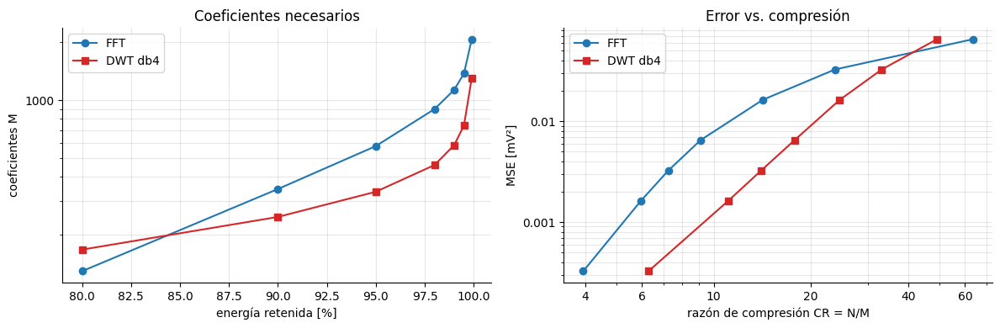

In [10]:
fracs = np.array([0.80, 0.90, 0.95, 0.98, 0.99, 0.995, 0.999])
curva = []
for fr in fracs:
    Xq, kq = comprimir_fft(x, frac=fr); cq, aa, aq, ss = comprimir_dwt(x, frac=fr, wavelet=WAV, nivel=NIVEL)
    curva.append(dict(energía=fr, M_F=int(kq.sum()), M_W=int(np.count_nonzero(aq)),
                      MSE_F=np.mean((x - np.real(ifft(Xq)))**2),
                      MSE_W=np.mean((x - pywt.waverec(cq, WAV, mode="periodization"))**2)))
curva = pd.DataFrame(curva)
curva["CR_F"], curva["CR_W"] = N/curva.M_F, N/curva.M_W
display(curva.style.format({"energía": "{:.3f}", "MSE_F": "{:.2e}", "MSE_W": "{:.2e}", "CR_F": "{:.1f}", "CR_W": "{:.1f}"}).hide(axis="index"))

from matplotlib.ticker import FuncFormatter
fmt = FuncFormatter(lambda v, _: f"{v:g}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogy(100*curva.energía, curva.M_F, "o-", color="C0", label="FFT"); ax[0].semilogy(100*curva.energía, curva.M_W, "s-", color="C3", label=f"DWT {WAV}")
ax[0].set(xlabel="energía retenida [%]", ylabel="coeficientes M", title="Coeficientes necesarios"); ax[0].legend(); ax[0].grid(alpha=.3, which="both")
ax[1].loglog(curva.CR_F, curva.MSE_F, "o-", color="C0", label="FFT"); ax[1].loglog(curva.CR_W, curva.MSE_W, "s-", color="C3", label=f"DWT {WAV}")
ax[1].set(xlabel="razón de compresión CR = N/M", ylabel="MSE [mV²]", title="Error vs. compresión"); ax[1].legend(); ax[1].grid(alpha=.3, which="both")
for a_ in ax: a_.yaxis.set_major_formatter(fmt)
ax[1].xaxis.set_major_formatter(fmt); ax[1].set_xticks([4, 6, 10, 20, 40, 60])
plt.tight_layout(); plt.savefig(FIG / "ej1_curva_CR_MSE.png", bbox_inches="tight"); plt.show()

# Mismo MSE ≈ mismo tramo de energía, pero con menos coeficientes: CR de la DWT respecto a la FFT por nivel de energía
RES["ej1_curva"] = {f"{100*r.energía:.1f}": dict(M_F=int(r.M_F), M_W=int(r.M_W)) for r in curva.itertuples()}

#### ¿Qué coeficientes se conservan? Frecuencia (FFT) frente a tiempo-escala (DWT)
Esta figura conecta el resultado con el principio de incertidumbre: la FFT solo informa de *qué frecuencias* hay; la DWT dice además *cuándo*.

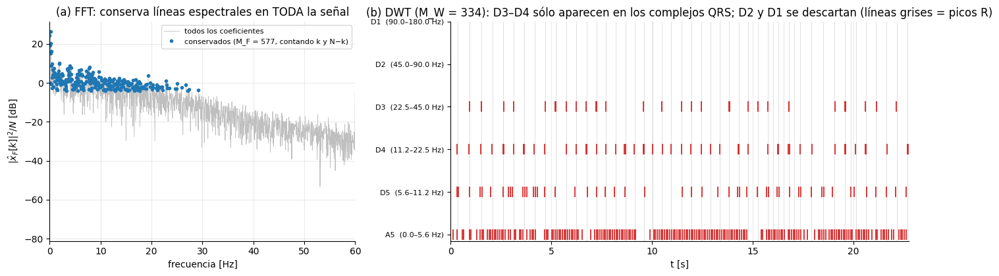

Las ventanas QRS ocupan el 25 % del tiempo. Coeficientes conservados que caen dentro de ellas:
  A5:  28.3 %  (198 conservados)
  D5:  65.4 %  (52 conservados)
  D4:  96.0 %  (50 conservados)
  D3: 100.0 %  (34 conservados)


In [11]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={"width_ratios": [1, 1.5]})
# (a) FFT: espectro y coeficientes conservados
mitad = slice(0, N//2)
P = 10 * np.log10(np.abs(X)**2 / N + 1e-12)
axs[0].plot(f_Hz[mitad], P[mitad], color="0.75", lw=.6, label="todos los coeficientes")
kk = keep_F[mitad]
axs[0].plot(f_Hz[mitad][kk], P[mitad][kk], "o", color="C0", ms=3, label=f"conservados (M_F = {M_F}, contando k y N−k)")
axs[0].set(xlim=(0, 60), xlabel="frecuencia [Hz]", ylabel=r"$|\hat x_F[k]|^2/N$ [dB]", title="(a) FFT: conserva líneas espectrales en TODA la señal")
axs[0].legend(loc="upper right", fontsize=8); axs[0].grid(alpha=.25)

# (b) DWT: dónde (en el tiempo) viven los coeficientes conservados, por subbanda
for tp in picos_R(x): axs[1].axvline(tp/FS, color="0.85", lw=.6, zorder=0)
for i, (nom, cq) in enumerate(zip(nombres, coefs_c)):
    j = NIVEL if nom == "A5" else int(nom[1])
    kidx = np.flatnonzero(cq)
    axs[1].plot((kidx + .5) * 2**j / FS, np.full(len(kidx), i), "|", color="C3", ms=11, mew=1.3)
axs[1].set_yticks(range(len(nombres))); axs[1].set_yticklabels([f"{r['subbanda']}  ({r['banda [Hz]']} Hz)" for r in filas_sb], fontsize=8)
axs[1].set(xlim=(0, N/FS), xlabel="t [s]", title=f"(b) DWT (M_W = {M_W}): D3–D4 sólo aparecen en los complejos QRS; D2 y D1 se descartan (líneas grises = picos R)")
axs[1].grid(alpha=.25, axis="x")
plt.tight_layout(); plt.savefig(FIG / "ej1_coeficientes_conservados.png", bbox_inches="tight"); plt.show()

# ¿Cuántos coeficientes conservados de cada subbanda caen dentro de ventanas QRS (±60 ms)?
w = int(0.06 * FS); pkq = picos_R(x); pkq = pkq[(pkq > w) & (pkq < N - w)]
mask_qrs = np.zeros(N, bool)
for p in pkq: mask_qrs[p-w:p+w+1] = True
alin = {}
for nom, cq in zip(nombres, coefs_c):
    j = NIVEL if nom == "A5" else int(nom[1]); kidx = np.flatnonzero(cq)
    if len(kidx):
        pos = np.clip(np.round((kidx + .5) * 2**j).astype(int), 0, N - 1)
        alin[nom] = dict(retenidos=int(len(kidx)), en_QRS_pct=float(100 * mask_qrs[pos].mean()))
print(f"Las ventanas QRS ocupan el {100*mask_qrs.mean():.0f} % del tiempo. Coeficientes conservados que caen dentro de ellas:")
for nom, d in alin.items(): print(f"  {nom}: {d['en_QRS_pct']:5.1f} %  ({d['retenidos']} conservados)")
RES["ej1_alineacion"] = dict(frac_tiempo_QRS_pct=float(100 * mask_qrs.mean()), **alin)

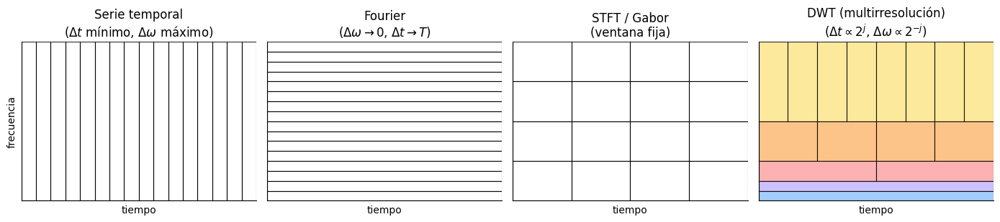

In [12]:
# Esquema de teselaciones tiempo–frecuencia (todas con celdas de área Δt·Δω constante ≥ 1/2)
def tesela(ax, celdas, titulo, colores=None):
    for i, (x0, y0, w, h) in enumerate(celdas):
        ax.add_patch(Rectangle((x0, y0), w, h, fc=(colores[i] if colores else "none"), ec="k", lw=.8, alpha=.85))
    ax.set(xlim=(0, 1), ylim=(0, 1), title=titulo, xlabel="tiempo"); ax.set_xticks([]); ax.set_yticks([])

fig, axs = plt.subplots(1, 4, figsize=(14, 3.2))
tesela(axs[0], [(i/16, 0, 1/16, 1) for i in range(16)], r"Serie temporal" "\n" r"($\Delta t$ mínimo, $\Delta\omega$ máximo)"); axs[0].set_ylabel("frecuencia")
tesela(axs[1], [(0, i/16, 1, 1/16) for i in range(16)], r"Fourier" "\n" r"($\Delta\omega\to 0$, $\Delta t\to T$)")
tesela(axs[2], [(i/4, k/4, 1/4, 1/4) for i in range(4) for k in range(4)], "STFT / Gabor\n(ventana fija)")
cel, col = [], []
paleta = ["#fde68a", "#fdba74", "#fca5a5", "#c4b5fd", "#93c5fd"]
for j, (lo, hi) in enumerate([(1/2, 1), (1/4, 1/2), (1/8, 1/4), (1/16, 1/8)], start=1):
    for i in range(2**(4-j)):
        cel.append((i/2**(4-j), lo, 1/2**(4-j), hi-lo)); col.append(paleta[j-1])
cel.append((0, 0, 1, 1/16)); col.append(paleta[4])
tesela(axs[3], cel, r"DWT (multirresolución)" "\n" r"($\Delta t\propto 2^{j}$, $\Delta\omega\propto 2^{-j}$)", col)
plt.tight_layout(); plt.savefig(FIG / "ej1_teselaciones.png", bbox_inches="tight"); plt.show()

---
## Discusión · Ejercicio 1 — ¿qué método preserva mejor los eventos transitorios?

**Respuesta corta.** La **DWT (db4, L = 5)**. Con la misma energía retenida (95 %) y, por tanto, el mismo MSE, necesita bastante menos coeficientes y conserva mejor la amplitud de los complejos QRS, que son el evento transitorio de esta señal. Tiene matices que se detallan al final: la ventaja es moderada y no es uniforme.

**1 · Resultados.** Segmento de trabajo ($N=8192$):

| | FFT | DWT (db4, L = 5) |
|---|---|---|
| Coeficientes $M$ (% de $N$) | 577 (7.04 %) | 334 (4.08 %) |
| Razón de compresión $CR=N/M$ | 14.2 | 24.5 |
| MSE [mV²] | 0.01629 | 0.01621 |
| SNR [dB] | 13.0 | 13.0 |

Los MSE coinciden (diferencia relativa máxima entre métodos en los 13 segmentos: 0.5%) porque **ambas bases son ortonormales**: por Parseval, $\mathrm{MSE}=\tfrac1N\times$(energía descartada), y los dos métodos descartan ≈ 5 %. El MSE, por sí solo, **no distingue** los métodos en este experimento; lo que cambia es *cuántos* coeficientes hacen falta y *dónde* cae el error. En los 13 segmentos no solapados del registro, la DWT necesita 289 ± 54 coeficientes frente a 515 ± 164 de la FFT (44 % menos; menor en 13/13 segmentos), es decir, $CR$ medio de 29.5 frente a 18.5. Si se da a la FFT el mismo número de coeficientes que usa la DWT, su MSE es 2.13 veces mayor (la DWT gana en 13/13).

**2 · Por qué: el principio de Heisenberg–Gabor.** Para cualquier función, $\Delta t\,\Delta\omega\ge \tfrac12$ (con $\Delta t,\Delta\omega$ las desviaciones típicas de $|f|^2$ y $|\hat f|^2$): no existe un átomo con localización perfecta en tiempo y en frecuencia a la vez, y cada base elige un punto de compromiso.

* **Fourier** elige $\Delta\omega\to0$ (frecuencia exacta) a costa de $\Delta t\to T$: sus átomos son sinusoides de soporte global. Un QRS dura ≈ 80 ms y es de banda ancha; para que una suma de sinusoides eternas sea cero fuera del QRS y grande dentro, hace falta que cientos de componentes **cancelen sus fases con precisión** en el resto del registro. Es una representación ineficiente (hay que conservar muchas líneas) y frágil: al descartar el 5 % de la energía la cancelación de fases deja de ser exacta y aparecen ondulaciones (*ringing*) alrededor del evento, visibles en el zoom de la figura de reconstrucción.
* **La DWT** usa átomos de soporte compacto cuya anchura crece con la escala: $\Delta t\propto 2^{j}$ y $\Delta\omega\propto 2^{-j}$ (el producto es constante; ver la figura de teselaciones). En las bandas de alta frecuencia (D3: 22.5–45 Hz, D4: 11.2–22.5 Hz) hay buena resolución temporal, justo donde vive la energía del QRS; en la banda lenta (A5: 0–5.6 Hz) hay buena resolución en frecuencia para la deriva de línea base y las ondas P/T.
* **Evidencia en los datos.** Los coeficientes de detalle conservados se alinean con los latidos: las ventanas QRS (±60 ms) ocupan el 25 % del tiempo y contienen el 100 % de los coeficientes conservados de D3 y el 96 % de los de D4; D2 y D1 (45–180 Hz; juntas, 0.35 % de la energía) se descartan por completo. Los coeficientes de la aproximación A5 (80 % de la energía) se reparten por todo el registro (28 % dentro de QRS). En consecuencia, la amplitud del pico R se conserva al 82.8% con la DWT frente a 72.3% con la FFT (mejor en 13/13 segmentos), y el RMS del error dentro de las ventanas QRS es 0.195 mV frente a 0.220 mV (menor en 13/13).

**3 · Matices (lo que este experimento no permite afirmar).**

1. **Ninguno de los dos preserva bien el QRS con el criterio del 95 %**: ambos atenúan el pico R en un 17–28 %. El criterio de energía está dominado por la línea base (A5 contiene el 80 % de la energía), y el QRS, con poca energía total, es lo primero que se sacrifica. Para fidelidad diagnóstica convendría umbralizar por banda o subir el umbral de energía.
2. **En el segmento de trabajo la diferencia en el error del QRS es mínima** (0.191 mV con DWT frente a 0.191 mV con FFT); su ventaja allí es sobre todo en $M$ y en la amplitud del pico R (0.81 frente a 0.68). La ventaja en el error QRS aparece al promediar los 13 segmentos (cociente FFT/DWT de 1.13).
3. **Fuera de los QRS gana la FFT**: RMS 0.098 mV frente a 0.112 mV (la DWT sólo es mejor en 1/13 segmentos). La DWT concentra su presupuesto en los transitorios y sacrifica detalle de baja amplitud (ondas P/T, ruido); es un buen trato sólo si lo que importa son los eventos.
4. **A baja retención la FFT necesita menos coeficientes** (con el 80 % de la energía: 129 frente a 167). Una explicación plausible (no verificada aquí) es que con tan poco detalle basta describir la deriva lenta, casi sinusoidal, para la que Fourier es eficiente. La ventaja de la DWT aparece cuando hay que reconstruir transitorios (≥ 90 % de energía: 345 frente a 247 coeficientes; ver curva de compromiso).
5. **Límites del estudio:** un solo registro (MIT-BIH 208) y una sola familia (db4); $CR=N/M$ cuenta coeficientes, no bits (no incluye el coste de guardar las posiciones de los coeficientes retenidos —que podría penalizar más a la DWT, cuyos coeficientes conservados están más dispersos (figura (b))— ni codificación entrópica).

**Conclusión del Ejercicio 1.** Para señales con transitorios sobre un fondo lento (ECG), la DWT ofrece mejor compromiso tiempo–frecuencia: mismo MSE con ≈ 44 % menos coeficientes y mejor conservación del QRS. La FFT sigue siendo preferible para componentes estacionarias/lentas y cuando se exige poca energía retenida.


---
# Ejercicio 2 · Aislamiento de fuentes puntuales en 2D (campo profundo)

**Objetivo.** Aislar las fuentes compactas (estrellas y galaxias distantes) de una imagen de campo profundo con dos herramientas: **2D-DWT** (umbralizado suave de los detalles, aproximación anulada) y **2D-FFT** (filtro pasa-altas gaussiano), y compararlas.

> **Sobre los datos.** La actividad pide una imagen del **JWST** (≥ 512 × 512 px, FITS o monocromática). La celda siguiente acepta un FITS de JWST (archivos `*_i2d.fits`, que guardan la imagen en la extensión `SCI`) o una imagen PNG/TIF/JPG, asignando su ruta a `RUTA_IMAGEN`; todos los umbrales se recalculan a partir de los datos. Si `RUTA_IMAGEN = None` se usa como **sustituto** el *Hubble eXtreme Deep Field* de *scikit-image* (872 × 1000 px, luminancia de 8 bits ya estirada, **no es JWST**); sirve para comprobar que el código funciona, pero no cumple lo que pide el enunciado.

In [13]:
RUTA_IMAGEN = "data/epico.tif"        # ← p. ej. "data/jwst_nircam_f200w_i2d.fits" o "data/jwst_deep_field.png"; None = Hubble XDF (sólo de respaldo)
MAX_LADO = 2048           # si la imagen es mayor, se usa un recorte de MAX_LADO × MAX_LADO (memoria y tiempo)
ORIGEN_RECORTE = None     # (fila, columna) de la esquina superior izquierda del recorte (ya sobre la imagen reducida); None = recorte centrado
REDUCIR = 3               # factor entero: promedia la imagen en bloques REDUCIR × REDUCIR antes de recortar (1 = no hacer nada). Útil si las estrellas salen muy anchas

def _gris_reducido(d, f=1):
    """Luminancia 2D (float64) de una imagen en gris, RGB/RGBA o con canales primero; con f > 1 la promedia en bloques f × f.
    Se procesa por BANDAS de filas: una imagen de ~1 Gpíxel no cabe entera en float64 (≈ 9 GB sólo en gris y ≈ 26 GB si se convierte el RGB completo)."""
    import warnings
    while d.ndim > 3: d = d[0]                                           # pila de páginas/canales extra
    if d.ndim == 3:
        if d.shape[-1] in (3, 4):   pass                                 # RGB / RGBA
        elif d.shape[0] in (3, 4):  d = np.moveaxis(d[:3], 0, -1)        # canales primero
        else:                       d = d[..., 0] if d.shape[-1] <= 2 else d[0]   # varias páginas: la primera
    f = max(1, int(f))
    h, w = (d.shape[0] // f) * f, (d.shape[1] // f) * f
    if (h // f) * (w // f) > 3e8:
        raise MemoryError(f"La imagen reducida mediría {h // f}×{w // f} px ({h * w / f**2 / 1e9:.2f} Gpíxeles): no cabe en memoria como decimales de 64 bits. "
                          f"Use un factor mayor: python construir.py --imagen ... --reducir {max(2, int(np.ceil((h * w / 1.5e8) ** 0.5)))} (o más).")
    sal = np.empty((h // f, w // f))
    paso = f * max(1, 4_000_000 // (w * f))                              # ≈ 4 Mpíxeles por banda
    for i in range(0, h, paso):
        b = d[i:min(i + paso, h), :w]
        g = rgb2gray(b[..., :3]) if b.ndim == 3 else np.asarray(b, dtype=float)
        if f > 1:
            g = g.reshape(g.shape[0] // f, f, w // f, f)
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")                          # bloques enteros de NaN → NaN (se rellenan después)
                g = np.nanmean(g, axis=(1, 3)) if np.isnan(g).any() else g.mean(axis=(1, 3))
        sal[i // f:i // f + g.shape[0]] = g
    return sal

def _leer_raster(ruta):
    """PNG/TIF/JPG → array. Un TIFF comprimido (LZW, etc.) necesita 'imagecodecs'; si falta, se prueba con Pillow."""
    from skimage import io
    try:
        return io.imread(ruta)
    except (ValueError, ImportError, RuntimeError) as e1:
        from PIL import Image
        try:
            with Image.open(ruta) as im:
                if im.mode in ("P", "PA"): im = im.convert("RGB")
                return np.asarray(im)
        except Exception as e2:
            raise RuntimeError(f"No se pudo leer {Path(ruta).name}.\n  scikit-image: {e1}\n  Pillow: {e2}\n"
                               "Si es un TIFF comprimido, instale el decodificador:  pip install imagecodecs") from e2

def leer_imagen(ruta, f=1):
    """Lee un FITS (JWST: extensión 'SCI') o una imagen PNG/TIF/JPG y devuelve un array 2D float (promediado en bloques f × f si f > 1)."""
    ruta = Path(ruta)
    if ruta.suffix.lower() in (".fits", ".fit", ".fz"):
        from astropy.io import fits
        with fits.open(ruta) as hdul:
            cand = [h for h in hdul if h.data is not None and np.ndim(h.data) >= 2]     # la HDU primaria de JWST está vacía
            if not cand:
                raise ValueError(f"{ruta.name}: ninguna extensión contiene una imagen 2D")
            h = next((h for h in cand if h.name.upper() == "SCI"), cand[0])
            d = h.data; nombre = f"{ruta.name} [extensión {h.name or 'primaria'}]"
            while d.ndim > 2: d = d[0]
            d = _gris_reducido(d, f)
    else:
        d = _gris_reducido(_leer_raster(ruta), f)
        nombre = f"{ruta.name} (imagen, luminancia)"
    return d, nombre

def cargar_imagen(ruta=None):
    lo = hi = None
    if ruta:
        d, nombre = leer_imagen(ruta, REDUCIR)
        if REDUCIR > 1: nombre += f" · promediada en bloques de {REDUCIR}×{REDUCIR}"
        malos = ~np.isfinite(d)
        s = int(np.ceil(np.sqrt(d.size / 1e7))) if d.size > 3e7 else 1    # imágenes enormes: las estadísticas globales se estiman con una submuestra
        if malos.any():                                                   # JWST: NaN fuera del campo cubierto
            d[malos] = np.nanmedian(d[::s, ::s])
        lo, hi = np.percentile(d[::s, ::s], [0.5, 99.95]); hi = max(hi, lo + 1e-12)
        fuente = f"{nombre} · normalizada con percentiles 0.5–99.95 → [0, 1] · {100*malos.mean():.1f} % de píxeles no finitos rellenados"
        del malos
    else:
        ruta_h = DATA / "hubble_deep_field_rgb.npy"
        if ruta_h.exists():
            rgb = np.load(ruta_h)
        else:                                                            # misma imagen, descargada por scikit-image (necesita red y pooch)
            from skimage import data as skdata
            rgb = skdata.hubble_deep_field()
        d = rgb2gray(rgb)
        fuente = "SUSTITUTO: Hubble eXtreme Deep Field (scikit-image), luminancia en [0, 1] — NO es JWST"
        if REDUCIR > 1:
            d = _gris_reducido(d, REDUCIR); fuente += f" · promediada en bloques de {REDUCIR}×{REDUCIR}"
    if min(d.shape) > MAX_LADO or max(d.shape) > MAX_LADO:                # recorte central si es muy grande
        y0, x0 = ORIGEN_RECORTE if ORIGEN_RECORTE else (max(0, (d.shape[0] - MAX_LADO) // 2), max(0, (d.shape[1] - MAX_LADO) // 2))
        d = d[y0:y0 + MAX_LADO, x0:x0 + MAX_LADO]; fuente += f" · recorte {d.shape[0]}×{d.shape[1]} desde (fila {y0}, col {x0})"
    if lo is not None:                                                    # se normaliza sólo el recorte (mismos valores que normalizar todo y recortar)
        d = np.clip((d - lo) / (hi - lo), 0, 1)
    H, W = (d.shape[0] // 4) * 4, (d.shape[1] // 4) * 4                  # múltiplos de 4 → L = 2 exacto
    if min(H, W) < 512: print(f"AVISO: la imagen mide {H}×{W}; el enunciado pide al menos 512×512")
    negro = np.mean(d[:H, :W] <= 0)
    if ruta and negro > 0.03:                                             # bordes vacíos (mosaicos): falsean el fondo y la normalización
        print(f"AVISO: el {100*negro:.1f} % de los píxeles es negro puro (¿bordes vacíos del mosaico?). Use --origen FILA COL "
              "para recortar una zona con señal; si no, el fondo (mediana) y los umbrales quedan falseados.")
    return d[:H, :W], fuente

img, fuente = cargar_imagen(RUTA_IMAGEN)
Hd, Wd = img.shape
MED = np.median(img)                                              # nivel del fondo
SIG = np.median(np.abs(img - MED)) / 0.6745                       # σ del fondo (MAD)
print(f"{fuente}\nTamaño: {Hd} × {Wd} px | rango [{img.min():.3f}, {img.max():.3f}] | fondo = {MED:.4f} ± {SIG:.4f} (MAD)")
RES.update(ej2_shape=[Hd, Wd], ej2_fondo=float(MED), ej2_sig_fondo=float(SIG), ej2_fuente=fuente, ej2_reducir=int(REDUCIR))

epico.tif (imagen, luminancia) · promediada en bloques de 3×3 · normalizada con percentiles 0.5–99.95 → [0, 1] · 0.0 % de píxeles no finitos rellenados · recorte 2048×2048 desde (fila 5343, col 4120)
Tamaño: 2048 × 2048 px | rango [0.233, 1.000] | fondo = 0.5133 ± 0.1205 (MAD)


### Parte 1 · Adquisición e inspección (escala logarítmica, `magma`)

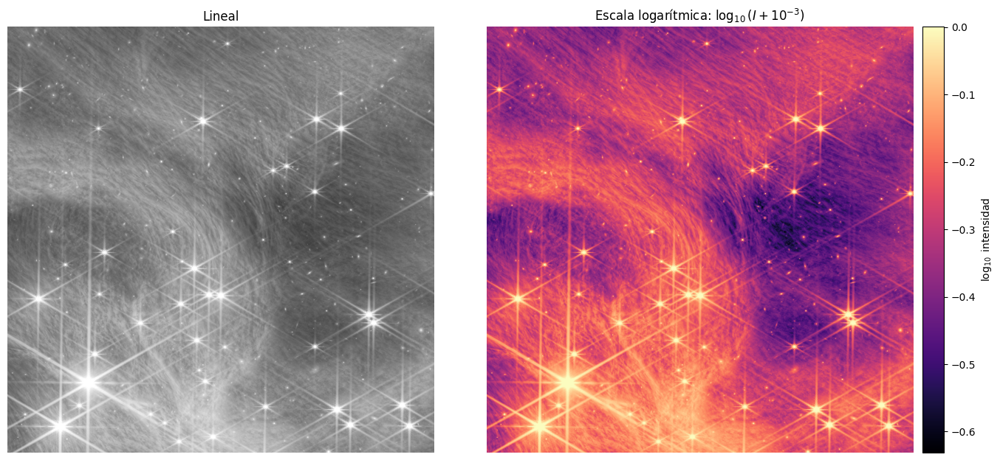

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6.3))
ax[0].imshow(img, cmap="gray", vmin=0, vmax=1); ax[0].set_title("Lineal")
im = ax[1].imshow(np.log10(img + 1e-3), cmap="magma"); ax[1].set_title(r"Escala logarítmica: $\log_{10}(I + 10^{-3})$")
plt.colorbar(im, ax=ax[1], fraction=.046, pad=.02, label=r"$\log_{10}$ intensidad")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### Parte 2 · 2D-DWT a nivel $L=2$ (`db2`, ortogonal y de soporte muy corto)
Se usa `mode="periodization"` (transformada ortogonal exacta). Subbandas: aproximación $cA_2$ y detalles $(cH_i, cV_i, cD_i)$, $i=1,2$ — horizontal, vertical y diagonal.

cA2: (512, 512) | nivel 2: (512, 512) | nivel 1: (1024, 1024)


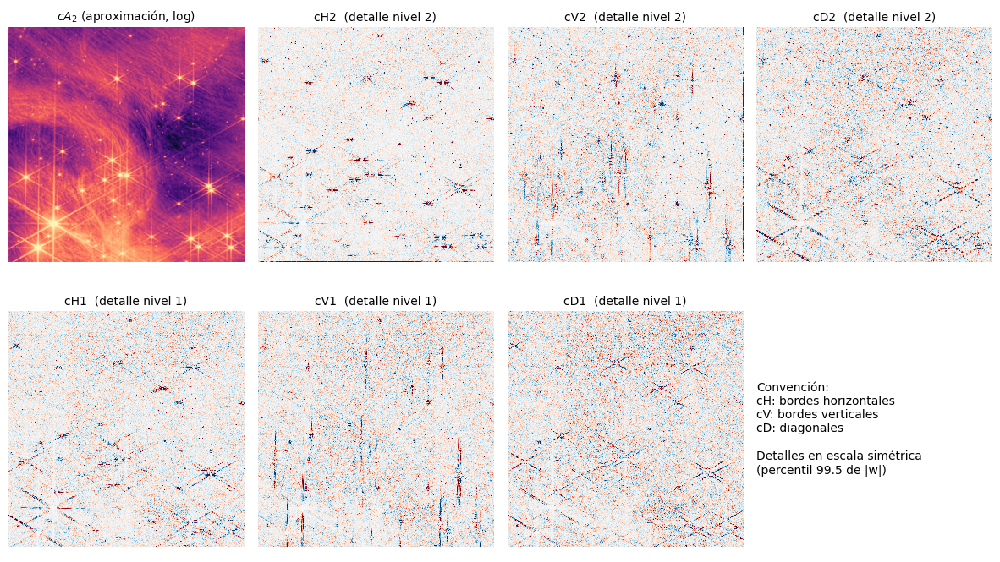

In [15]:
WAV2, L2 = "db2", 2
coefs2 = pywt.wavedec2(img, WAV2, level=L2, mode="periodization")
cA2, (cH2, cV2, cD2), (cH1, cV1, cD1) = coefs2
print("cA2:", cA2.shape, "| nivel 2:", cH2.shape, "| nivel 1:", cH1.shape)

def mostrar_detalle(ax, w, titulo):
    a = np.percentile(np.abs(w), 99.5)
    ax.imshow(w, cmap="RdBu_r", vmin=-a, vmax=a, interpolation="nearest"); ax.set_title(titulo, fontsize=10); ax.axis("off")

fig = plt.figure(figsize=(15, 8.2)); gs = gridspec.GridSpec(2, 4, wspace=.06, hspace=.14)
a = fig.add_subplot(gs[0, 0]); a.imshow(np.log10(np.clip(cA2 / 2**L2, 0, None) + 1e-3), cmap="magma"); a.set_title(r"$cA_2$ (aproximación, log)", fontsize=10); a.axis("off")
for k, (w, n) in enumerate([(cH2, "cH2"), (cV2, "cV2"), (cD2, "cD2")], start=1): mostrar_detalle(fig.add_subplot(gs[0, k]), w, f"{n}  (detalle nivel 2)")
for k, (w, n) in enumerate([(cH1, "cH1"), (cV1, "cV1"), (cD1, "cD1")]): mostrar_detalle(fig.add_subplot(gs[1, k]), w, f"{n}  (detalle nivel 1)")
a = fig.add_subplot(gs[1, 3]); a.axis("off")
a.text(0, .5, "Convención:\ncH: bordes horizontales\ncV: bordes verticales\ncD: diagonales\n\nDetalles en escala simétrica\n(percentil 99.5 de |w|)", va="center", fontsize=10)
plt.show()

### Parte 3 · 2D-FFT centrada: espectro de magnitud logarítmica y espectro de fase

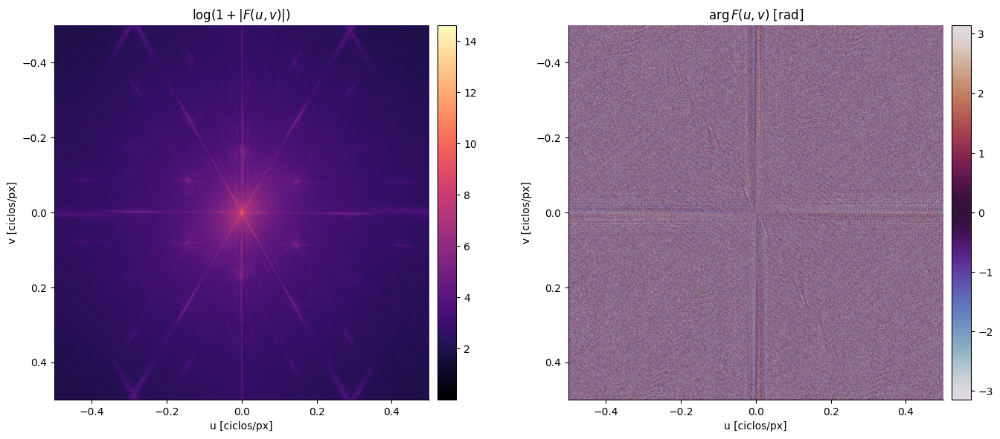

In [16]:
F = fftshift(fft2(img))                                          # espectro centrado
fxc, fyc = fftshift(fftfreq(Wd)), fftshift(fftfreq(Hd))          # ciclos/píxel
ext = [fxc[0], fxc[-1], fyc[-1], fyc[0]]
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
i0 = ax[0].imshow(np.log1p(np.abs(F)), cmap="magma", extent=ext); ax[0].set_title(r"$\log(1+|F(u,v)|)$")
plt.colorbar(i0, ax=ax[0], fraction=.046, pad=.02)
i1 = ax[1].imshow(np.angle(F), cmap="twilight", extent=ext, vmin=-np.pi, vmax=np.pi); ax[1].set_title(r"$\arg F(u,v)$ [rad]")
plt.colorbar(i1, ax=ax[1], fraction=.046, pad=.02)
for a in ax: a.set(xlabel="u [ciclos/px]", ylabel="v [ciclos/px]")
plt.tight_layout(); plt.show()

La energía se concentra en torno a $(u,v)=(0,0)$ (estructura de gran escala y fondo) y decae radialmente; la "cruz" sobre los ejes procede de la discontinuidad entre bordes opuestos de la imagen (la DFT supone periodicidad). **La fase**, aparentemente ruidosa, es la que codifica *dónde* está cada fuente: un objeto puntual en $(x_0,y_0)$ aporta un factor $e^{-i2\pi(ux_0+vy_0)}$ a todas las frecuencias.

### Parte 4 · Aislamiento con wavelets: $cA_2=0$ + umbralizado suave $S_\lambda(w)=\operatorname{sign}(w)\max(|w|-\lambda,0)$

**Elección de $\lambda$ (justificada, no arbitraria).** El ruido del fondo se estima con el estimador robusto MAD sobre el detalle diagonal más fino, $\hat\sigma=\operatorname{mediana}(|cD_1|)/0.6745$, y se aplica el umbral universal de Donoho–Johnstone, $\lambda=\hat\sigma\sqrt{2\ln n}$ ($n$ = número de píxeles). Anular $cA_2$ elimina las componentes de baja frecuencia ($< 1/8$ ciclos/px aprox.): el fondo suave y el interior de objetos extensos.

In [17]:
def umbral_suave(w, lam): return np.sign(w) * np.maximum(np.abs(w) - lam, 0.0)
def umbral_duro(w, lam):  return w * (np.abs(w) > lam)

def aislar_wavelet(imagen, lam, wavelet=WAV2, nivel=L2, tipo="suave", coefs=None):
    """cA = 0 + umbralizado de los detalles + reconstrucción 2D-IDWT."""
    if coefs is None:
        coefs = pywt.wavedec2(imagen, wavelet, level=nivel, mode="periodization")
    u = umbral_suave if tipo == "suave" else umbral_duro
    nuevo = [np.zeros_like(coefs[0])] + [tuple(u(d, lam) for d in det) for det in coefs[1:]]
    return pywt.waverec2(nuevo, wavelet, mode="periodization")

SIGMA_W = np.median(np.abs(cD1)) / 0.6745                         # ruido del fondo en la escala de los detalles
LAM = SIGMA_W * np.sqrt(2 * np.log(img.size))                     # umbral universal (VisuShrink)
f_wav = aislar_wavelet(img, LAM, coefs=coefs2)
det_todos = np.concatenate([d.ravel() for det in coefs2[1:] for d in det])
sobrev = np.mean(np.abs(det_todos) > LAM)
print(f"σ̂ (MAD de cD1) = {SIGMA_W:.4f}   |   λ = σ̂·√(2 ln n) = {LAM:.4f}   ({LAM/SIGMA_W:.2f} σ̂)")
print(f"Coeficientes de detalle que sobreviven al umbral: {100*sobrev:.2f} %  ({int(sobrev*det_todos.size)} de {det_todos.size})")
RES.update(ej2_sigma_w=float(SIGMA_W), ej2_lambda=float(LAM), ej2_sobrev_pct=float(100*sobrev))

σ̂ (MAD de cD1) = 0.0057   |   λ = σ̂·√(2 ln n) = 0.0314   (5.52 σ̂)
Coeficientes de detalle que sobreviven al umbral: 3.96 %  (155792 de 3932160)


### Parte 5 · Aislamiento con 2D-FFT: filtro pasa-altas gaussiano
$H(u,v)=1-\exp\!\left(-\dfrac{D^2(u,v)}{2D_0^2}\right)$, con $D$ la distancia al centro del espectro desplazado (en ciclos/píxel).

**Elección de $D_0$ (comparación en igualdad de condiciones).** Anular $cA_2$ en la DWT equivale a cortar por debajo de $f_c=1/8$ ciclos/px (borde de la banda de aproximación del nivel 2). Se fija $D_0$ para que el filtro gaussiano valga **0.5 justo en $f_c$**: $H(f_c)=0.5\Rightarrow D_0=f_c/\sqrt{2\ln 2}\approx 0.106$ ciclos/px.

In [18]:
FC = 1/8                                                    # ciclos/px: borde de la aproximación del nivel 2
D0 = FC / np.sqrt(2 * np.log(2))                            # H(FC) = 0.5

def filtro_fft(imagen, tipo="gauss", D0=D0):
    """2D-FFT centrada → filtro pasa-altas H(u,v) → transformada inversa (parte real)."""
    Fc = fftshift(fft2(imagen))
    u, v = fftshift(fftfreq(imagen.shape[1])), fftshift(fftfreq(imagen.shape[0]))
    Dd = np.hypot(*np.meshgrid(u, v))                       # D(u,v) [ciclos/px]
    Hh = 1 - np.exp(-Dd**2 / (2 * D0**2)) if tipo == "gauss" else (Dd > D0).astype(float)   # "ideal": corte abrupto
    return np.real(ifft2(ifftshift(Fc * Hh)))

f_fft   = filtro_fft(img, "gauss")                          # el filtro pedido en el enunciado
f_ideal = filtro_fft(img, "ideal")                          # variante de CORTE ABRUPTO (se usa en la pregunta B)
print(f"D0 = {D0:.4f} ciclos/px  →  H(f_c = 1/8) = {1-np.exp(-FC**2/(2*D0**2)):.2f}")
RES["ej2_D0"] = float(D0)

D0 = 0.1062 ciclos/px  →  H(f_c = 1/8) = 0.50


### Parte 6 · Evaluación comparativa — panel 2 × 2
Original (escala log) · $f_{wavelet}$ · $f_{fft}$ · $|f_{wavelet}-f_{fft}|$. Las dos imágenes filtradas se muestran con **la misma escala lineal** (los valores negativos —halos— se recortan a negro en la visualización; se cuantifican en la tabla de abajo).

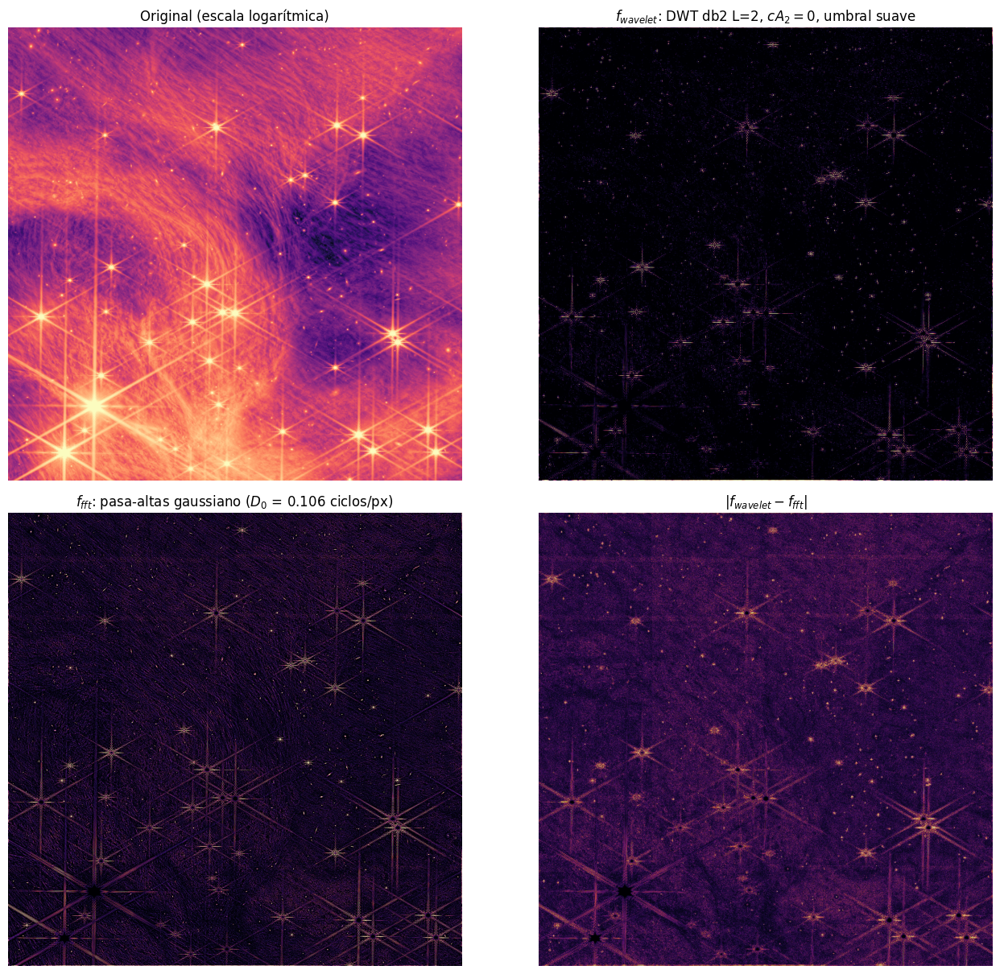

In [19]:
vmax = np.percentile(np.maximum(np.maximum(f_wav, f_fft), 0), 99.5)
fig, ax = plt.subplots(2, 2, figsize=(14, 12.2))
ax[0, 0].imshow(np.log10(img + 1e-3), cmap="magma"); ax[0, 0].set_title("Original (escala logarítmica)")
ax[0, 1].imshow(f_wav, cmap="magma", vmin=0, vmax=vmax); ax[0, 1].set_title(r"$f_{wavelet}$: DWT db2 L=2, $cA_2=0$, umbral suave")
ax[1, 0].imshow(f_fft, cmap="magma", vmin=0, vmax=vmax); ax[1, 0].set_title(r"$f_{fft}$: pasa-altas gaussiano ($D_0$ = %.3f ciclos/px)" % D0)
ax[1, 1].imshow(np.abs(f_wav - f_fft), cmap="inferno", vmin=0, vmax=vmax); ax[1, 1].set_title(r"$|f_{wavelet}-f_{fft}|$")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(FIG / "ej2_panel_2x2.png", bbox_inches="tight", dpi=110); plt.show()

#### Evidencia cuantitativa para la discusión
Se seleccionan **fuentes de referencia** (máximos locales que destacan del fondo) y se mide, para cada método: (i) **posición** (¿el máximo local queda a ≤ 1 px del original?), (ii) **retención del pico**, (iii) **correlación de forma** (recorte 11×11 vs. original), (iv) **RMS en cielo vacío** (≥ 14 px de cualquier objeto) y (v) **halo**: media y mínimo del anillo 4–10 px alrededor de la fuente, normalizados por su amplitud (negativo ⇒ sub-oscilación).

**Criterio de selección.** *Estricto* (el habitual): fuentes **compactas** (área a mitad de máximo ≤ 12 px) y **aisladas** (en el borde de una ventana de 15 × 15 px la señal cae por debajo del 35 % de la amplitud); el umbral de detección baja 15σ → 10σ → 6σ → 4σ hasta reunir ≥ 30. **Si la imagen no tiene al menos 10 fuentes así** (típico de imágenes muy sobremuestreadas, con nebulosidad intensa o muy pobladas) el cuaderno cambia a un criterio *adaptativo*: detecta sobre la imagen sin el fondo suave y **relaja poco a poco** el área (hasta 80 px) y el aislamiento (hasta el 65 %). Imprime cuál acabó usando, lo guarda en `resultados.json` y la discusión lo menciona: con el criterio relajado las fuentes ya no son «puntuales» en sentido estricto. **Comprueben siempre la figura de selección** (siguiente celda): las fuentes elegidas deben ser estrellas o galaxias compactas, no filamentos de nebulosa.

In [20]:
def _medir(imagen, y, x0):
    """Amplitud sobre el fondo local, área a mitad de máximo y máximo del borde de la ventana 15×15 centrada en (y, x0)."""
    p = imagen[y-7:y+8, x0-7:x0+8]; fondo = np.median(p)
    amp = imagen[y-1:y+2, x0-1:x0+2].max() - fondo
    lab, _ = ndi.label(p > fondo + 0.5 * amp)
    area = np.sum(lab == lab[7, 7]) if lab[7, 7] > 0 else 999
    borde = np.r_[p[0], p[-1], p[:, 0], p[:, -1]]
    return amp, area, borde.max(), fondo

def residuo(imagen):
    """Imagen sin la nebulosidad ni los gradientes suaves (σ = 20 px) y su σ robusto: permite detectar en campos con fondo estructurado."""
    bgs = ndi.gaussian_filter(imagen, 1); res = bgs - ndi.gaussian_filter(bgs, 20)
    return res, np.median(np.abs(res - np.median(res))) / 0.6745

def fuentes_puntuales(imagen, n_max=150, area_max=12, minimas=30, suficientes=10):
    """Fuentes de referencia → (posiciones, amplitudes, criterio aplicado).
    1) ESTRICTO: compactas (área a mitad de máximo ≤ area_max) y aisladas (borde de la ventana < 35 % de la amplitud); el umbral
       de detección baja 15σ → 10σ → 6σ → 4σ hasta reunir 'minimas'. Es lo que se usa si salen al menos 'suficientes'.
    2) ADAPTATIVO (imágenes sobremuestreadas, con nebulosidad o muy pobladas): detección sobre la imagen residual y relajación
       gradual del área y del aislamiento.
    3) SIN FILTRO DE FORMA (último recurso, si lo anterior da < 5): los máximos más brillantes."""
    # --- 1) criterio estricto
    bgs = ndi.gaussian_filter(imagen, 1)
    for k in (15, 10, 6, 4):
        cand = peak_local_max(bgs, min_distance=8, threshold_abs=MED + k*SIG, exclude_border=14)
        info = []
        for y, x0 in cand:
            amp, area, bmax, fondo = _medir(imagen, y, x0)
            if area <= area_max and bmax < fondo + 0.35 * amp:
                info.append((y, x0, amp, area))
        if len(info) >= minimas: break
    n_estricto = len(info)
    crit = dict(modo="estricto", area_max=int(area_max), aislamiento=0.35, k_sigma=int(k))
    if n_estricto < suficientes:
        # --- 2) criterio adaptativo
        res, sig_res = residuo(imagen)
        cand = peak_local_max(res, min_distance=8, threshold_abs=4*sig_res, exclude_border=14, num_peaks=4000)
        med = [(y, x0, *_medir(imagen, y, x0), res[y, x0] / sig_res) for y, x0 in cand]     # y, x0, amp, área, borde, fondo, nivel (σ)
        def elegir(am, ais, kk):
            return [(y, x0, amp, area) for y, x0, amp, area, bmax, fondo, nivel in med
                    if amp > 0 and area <= am and bmax < fondo + ais * amp and nivel >= kk]
        elegido = None
        for am, ais in ((area_max, .35), (25, .45), (50, .55), (80, .65)):               # primero se relaja la forma ...
            for kk in (15, 10, 6, 4):                                                    # ... y, dentro de cada forma, el umbral
                sel = elegir(am, ais, kk)
                if len(sel) >= minimas: elegido = (sel, am, ais, kk); break
            if elegido: break
        if elegido is None: elegido = (elegir(80, .65, 4), 80, .65, 4)                   # ninguno llega a 'minimas': el más laxo
        n_adapt = len(elegido[0])
        if max(n_estricto, n_adapt) >= 5:
            if n_adapt >= n_estricto:
                info = elegido[0]
                crit = dict(modo="adaptativo", area_max=int(elegido[1]), aislamiento=float(elegido[2]), k_sigma=int(elegido[3]))
        else:                                                                            # --- 3) sin filtro de forma
            info = [(y, x0, amp, area) for y, x0, amp, area, bmax, fondo, nivel in med if amp > 0 and nivel >= 4]
            crit = dict(modo="sin filtro", area_max=None, aislamiento=None, k_sigma=4)
        crit["n_candidatas"] = int(len(med))
    if len(info) == 0:
        raise RuntimeError("No se encontró ninguna fuente brillante; revise la imagen (¿está vacía o es constante?).")
    info = np.array(info, dtype=float); info = info[np.argsort(info[:, 2])[::-1]][:n_max]
    crit.update(n=int(len(info)), area_mediana=float(np.median(info[:, 3])), n_estricto=int(n_estricto))
    crit["relajado"] = bool(crit["modo"] == "sin filtro" or (crit["modo"] == "adaptativo" and (crit["area_max"] > area_max or crit["aislamiento"] > 0.35)))   # ¿se aflojó el criterio de FORMA?
    return info[:, :2].astype(int), info[:, 2], crit

fuentes, amps, crit = fuentes_puntuales(img)
if crit["modo"] == "estricto":
    obj4, obj15 = img > MED + 4*SIG, img > MED + 15*SIG                    # caso habitual: el fondo es plano
else:                                                                     # fondo estructurado: los objetos se definen sobre la imagen residual
    res_, sig_res_ = residuo(img); obj4, obj15 = res_ > 4*sig_res_, res_ > 15*sig_res_
cielo = ~ndi.binary_dilation(obj4, iterations=14)                         # cielo vacío
for it in (8, 4, 2):                                                      # campo muy poblado: reducir la distancia de seguridad
    if cielo.mean() >= 0.02: break
    cielo = ~ndi.binary_dilation(obj4, iterations=it)
    print(f"AVISO: poco cielo vacío; distancia de seguridad reducida a {it} px")
if cielo.sum() < 1000:
    cielo = ~obj4; print("AVISO: casi no hay cielo vacío; se usa todo píxel fuera de los objetos detectados")
cerca = ndi.binary_dilation(obj15, iterations=10) & ~cielo                # alrededor de fuentes brillantes
yy_, xx_ = np.ogrid[-10:11, -10:11]; rr_ = np.hypot(yy_, xx_); anillo = (rr_ >= 4) & (rr_ <= 10)
etq = {"estricto": "compactas y aisladas", "sin filtro": "SIN filtro de forma",
       "adaptativo": "con criterio RELAJADO" if crit["relajado"] else "compactas y aisladas (detectadas sobre la imagen residual)"}[crit["modo"]]
print(f"{len(fuentes)} fuentes {etq} | criterio: {crit['modo']}"
      + (f" (área ≤ {crit['area_max']} px, aislamiento < {crit['aislamiento']:.0%}, ≥ {crit['k_sigma']}σ)" if crit["area_max"] else "")
      + f" | área mediana = {crit['area_mediana']:.0f} px | cielo vacío = {100*cielo.mean():.1f} % de los píxeles")
if crit["modo"] == "adaptativo" and not crit["relajado"]:
    print("NOTA: el fondo es estructurado (nebulosa o gradientes), así que las fuentes se detectaron sobre la imagen residual; la forma exigida es la misma (área ≤ 12 px, aislamiento < 35 %).")
if crit["relajado"]:
    print(f"AVISO: con el criterio estricto (área ≤ 12 px, aislamiento < 35 %) sólo había {crit['n_estricto']} fuentes; las de referencia son más "
          "extensas que un punto. Compruebe en la figura siguiente que son fuentes reales y no filamentos de nebulosa.")
fwhm_ = 2 * np.sqrt(crit["area_mediana"] / np.pi)                          # FWHM equivalente de una fuente circular con esa área a mitad de máximo
if fwhm_ > 4.5:
    k_ = int(max(2, round(fwhm_ / 2.2)))
    print(f"AVISO: las fuentes miden ≈ {fwhm_:.1f} px de FWHM (una estrella a la escala de píxel natural mide 1–3 px). El filtro del enunciado (corte en 1/8 ciclos/px, L = 2) "
          f"elimina buena parte de su energía, así que las comparaciones del Ejercicio 2 valdrán sólo para esa escala. Para fuentes más finas: python construir.py --imagen ... --reducir {REDUCIR * k_}")
RES["ej2_criterio_fuentes"] = crit
RES["ej2_n_fuentes"] = int(len(fuentes))

37 fuentes compactas y aisladas (detectadas sobre la imagen residual) | criterio: adaptativo (área ≤ 12 px, aislamiento < 35%, ≥ 10σ) | área mediana = 9 px | cielo vacío = 85.5 % de los píxeles
NOTA: el fondo es estructurado (nebulosa o gradientes), así que las fuentes se detectaron sobre la imagen residual; la forma exigida es la misma (área ≤ 12 px, aislamiento < 35 %).


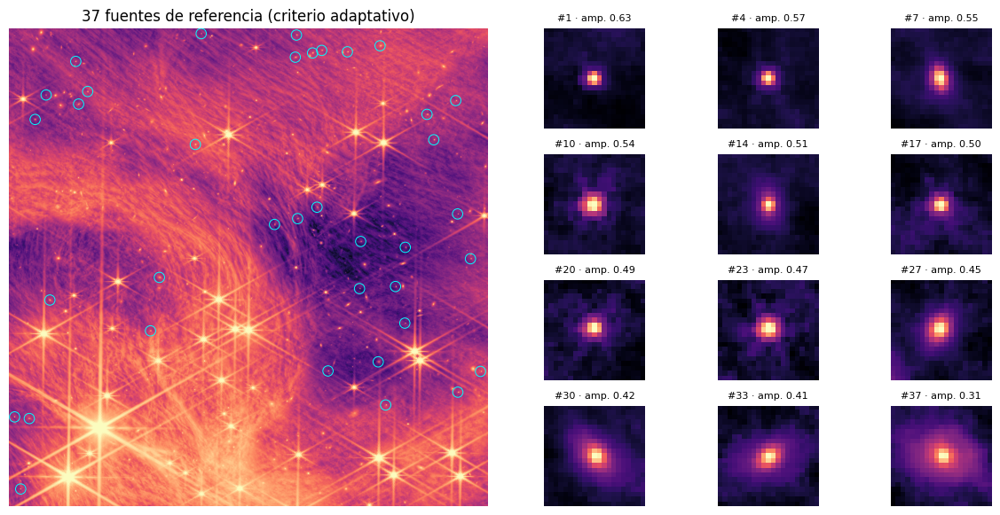

In [21]:
# Comprobación visual de la selección: posiciones sobre la imagen y 12 recortes (de la más brillante a la más tenue)
sel_g = np.linspace(0, len(fuentes) - 1, 12).astype(int)
fig = plt.figure(figsize=(15, 7)); gs = gridspec.GridSpec(4, 6, figure=fig, wspace=.05, hspace=.25)
a0 = fig.add_subplot(gs[:, :3]); a0.imshow(np.log10(img + 1e-3), cmap="magma")
a0.scatter(fuentes[:, 1], fuentes[:, 0], s=70, facecolors="none", edgecolors="cyan", linewidths=.7)
a0.set_title(f"{len(fuentes)} fuentes de referencia (criterio {crit['modo']})"); a0.axis("off")
for j, i in enumerate(sel_g):
    a = fig.add_subplot(gs[j // 3, 3 + j % 3]); y, x0 = fuentes[i]
    a.imshow(img[y-10:y+11, x0-10:x0+11], cmap="magma", interpolation="nearest"); a.set_title(f"#{i + 1} · amp. {amps[i]:.2f}", fontsize=8); a.axis("off")
plt.savefig(FIG / "ej2_fuentes_seleccionadas.png", bbox_inches="tight", dpi=110); plt.show()

In [22]:
def evaluar_fuentes(f):
    desp, ret, cor, anil, lob = [], [], [], [], []
    for (y, x0), a in zip(fuentes, amps):
        sub = f[y-2:y+3, x0-2:x0+3]; dy, dx = np.unravel_index(np.argmax(sub), sub.shape)
        desp.append(np.hypot(dy-2, dx-2)); ret.append(sub.max() / a)
        cor.append(np.corrcoef(img[y-5:y+6, x0-5:x0+6].ravel(), f[y-5:y+6, x0-5:x0+6].ravel())[0, 1])
        pr = f[y-10:y+11, x0-10:x0+11]; anil.append(pr[anillo].mean() / a); lob.append(pr[anillo].min() / a)
    desp = np.array(desp)
    return {"posición ≤1 px": np.mean(desp <= 1), "retención del pico": np.mean(ret), "correlación de forma": np.mean(cor),
            "RMS en cielo vacío": np.sqrt(np.mean(f[cielo]**2)), "halo medio / amp.": np.mean(anil), "halo mínimo / amp.": np.mean(lob)}

metodos = {"Wavelet db2 L=2 · umbral suave (enunciado)": f_wav,
           "Wavelet db2 L=2 · umbral duro": aislar_wavelet(img, LAM, coefs=coefs2, tipo="duro"),
           "FFT pasa-altas gaussiano (enunciado)": f_fft,
           "FFT pasa-altas ideal (corte abrupto)": f_ideal}
tabla_A = pd.DataFrame({k: evaluar_fuentes(v) for k, v in metodos.items()}).T
display(tabla_A.style.format("{:.3f}"))
print(f"(Referencia: RMS del ruido de fondo de la imagen original = {SIG:.4f})")
RES["ej2_tabla_A"] = {k: {c: float(v) for c, v in fila.items()} for k, fila in tabla_A.iterrows()}
RES["ej2_n_fuentes"] = int(len(fuentes))

,posición ≤1 px,retención del pico,correlación de forma,RMS en cielo vacío,halo medio / amp.,halo mínimo / amp.
Wavelet db2 L=2 · umbral suave (enunciado),0.919,0.471,0.597,0.005,-0.002,-0.139
Wavelet db2 L=2 · umbral duro,0.973,0.552,0.613,0.009,-0.003,-0.177
FFT pasa-altas gaussiano (enunciado),1.000,0.514,0.881,0.011,-0.007,-0.097
FFT pasa-altas ideal (corte abrupto),1.000,0.590,0.815,0.013,0.003,-0.167


(Referencia: RMS del ruido de fondo de la imagen original = 0.1205)


**¿Depende la conclusión de los parámetros elegidos?** Se repite la evaluación variando el umbral de la wavelet ($\lambda=2,3,4\hat\sigma$ y el universal $5.2\hat\sigma$) y la frecuencia de corte del filtro gaussiano ($f_c=1/16,\,1/8,\,1/4$ ciclos/px, con $D_0=f_c/\sqrt{2\ln 2}$).

In [23]:
filas_s = {}
for k in (2, 3, 4, LAM / SIGMA_W):
    filas_s[f"Wavelet suave · λ = {k:.1f} σ̂"] = evaluar_fuentes(aislar_wavelet(img, k * SIGMA_W, coefs=coefs2))
for fc in (1/16, 1/8, 1/4):
    filas_s[f"FFT gaussiano · f_c = 1/{round(1/fc)}"] = evaluar_fuentes(filtro_fft(img, "gauss", D0=fc / np.sqrt(2 * np.log(2))))
tabla_S = pd.DataFrame(filas_s).T[["posición ≤1 px", "retención del pico", "correlación de forma", "RMS en cielo vacío", "halo mínimo / amp."]]
display(tabla_S.style.format("{:.3f}"))
RES["ej2_tabla_sens"] = {k: {c: float(v) for c, v in fila.items()} for k, fila in tabla_S.iterrows()}

,posición ≤1 px,retención del pico,correlación de forma,RMS en cielo vacío,halo mínimo / amp.
Wavelet suave · λ = 2.0 σ̂,1.000,0.521,0.616,0.008,-0.159
Wavelet suave · λ = 3.0 σ̂,0.946,0.506,0.612,0.007,-0.153
Wavelet suave · λ = 4.0 σ̂,0.946,0.491,0.606,0.006,-0.147
Wavelet suave · λ = 5.5 σ̂,0.919,0.471,0.597,0.005,-0.139
FFT gaussiano · f_c = 1/16,1.000,0.803,0.978,0.016,-0.124
FFT gaussiano · f_c = 1/8,1.000,0.514,0.881,0.011,-0.097
FFT gaussiano · f_c = 1/4,1.000,0.223,0.746,0.007,-0.054


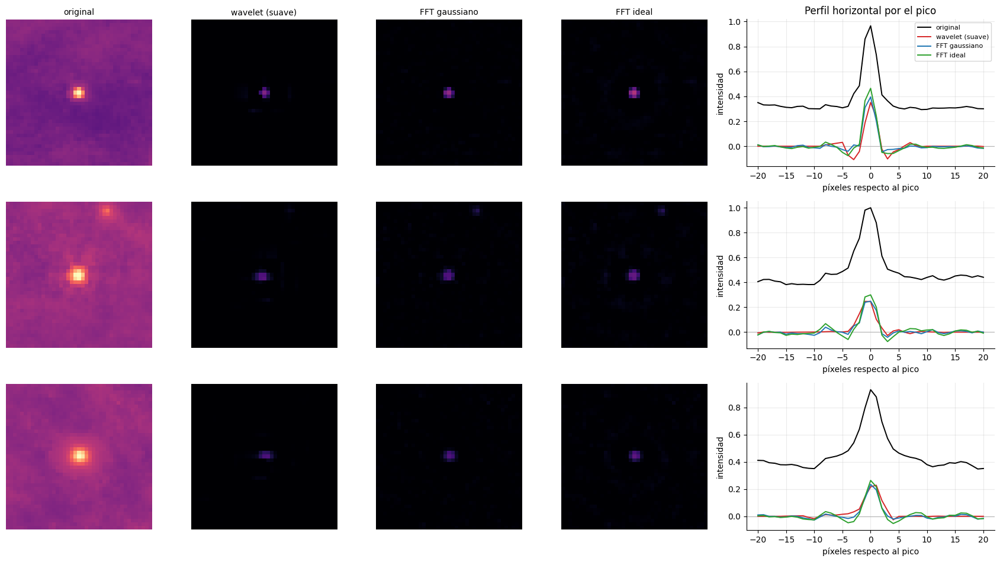

In [24]:
# Recortes y perfiles 1D a través de tres fuentes (brillante, intermedia, tenue)
sel = [0, len(fuentes)//4, len(fuentes)//2]
mt = {"original": img, "wavelet (suave)": f_wav, "FFT gaussiano": f_fft, "FFT ideal": f_ideal}
fig, ax = plt.subplots(3, 5, figsize=(17, 9.6), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.7]})
for r, i in enumerate(sel):
    y, x0 = fuentes[i]; ya, xa = np.clip(y-20, 0, Hd-41), np.clip(x0-20, 0, Wd-41)
    for c, (nom, f) in enumerate(mt.items()):
        ax[r, c].imshow(f[ya:ya+41, xa:xa+41], cmap="magma", vmin=0 if c else 0, vmax=img[y-2:y+3, x0-2:x0+3].max()); ax[r, c].axis("off")
        if r == 0: ax[r, c].set_title(nom, fontsize=10)
    ax[r, 4].axhline(0, color="0.7", lw=.8)
    for nom, f, col in (("original", img, "k"), ("wavelet (suave)", f_wav, "C3"), ("FFT gaussiano", f_fft, "C0"), ("FFT ideal", f_ideal, "C2")):
        ax[r, 4].plot(np.arange(-20, 21), f[y, x0-20:x0+21] if x0-20 >= 0 and x0+21 <= Wd else np.zeros(41), color=col, lw=1.4, label=nom)
    ax[r, 4].set(xlabel="píxeles respecto al pico", ylabel="intensidad"); ax[r, 4].grid(alpha=.25)
    if r == 0: ax[r, 4].legend(fontsize=8); ax[r, 4].set_title("Perfil horizontal por el pico")
plt.tight_layout(); plt.savefig(FIG / "ej2_perfiles_fuentes.png", bbox_inches="tight"); plt.show()

### Pregunta B · ¿Por qué la FFT produce oscilaciones (Gibbs) y las wavelets no? — experimentos

**Experimento 1 — respuesta al impulso.** Se inyecta una fuente puntual (gaussiana de $\sigma=1$ px, amplitud 0.9) en una imagen vacía y se mide qué hace cada filtro con ella: forma del perfil, número de cambios de signo y **radio que contiene el 99 % de la energía de la respuesta** (extensión espacial del artefacto).

,pico / entrada,lóbulo negativo mín. / pico,cambios de signo,radio 99 % energía [px]
filtro,,,,
FFT gaussiano,0.692,-0.103,1,4.000
FFT ideal (corte abrupto),0.800,-0.134,3,42.000
Wavelet db2 L=2 (umbral suave),0.368,-0.584,4,6.000


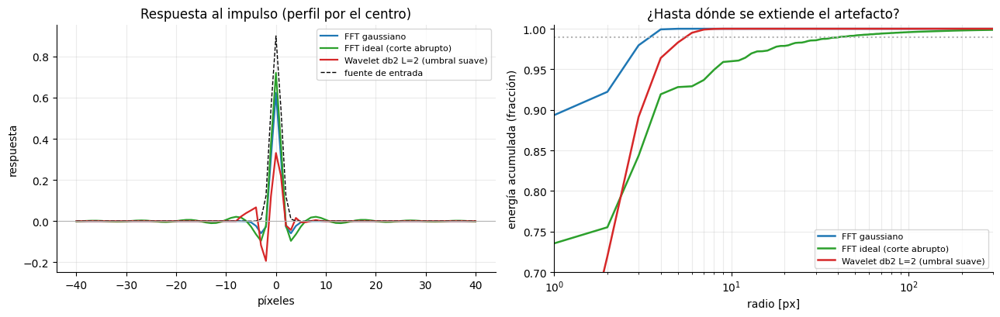

In [25]:
cy, cx = Hd // 2, Wd // 2
yy, xx = np.mgrid[0:Hd, 0:Wd]
src = 0.9 * np.exp(-((yy - cy)**2 + (xx - cx)**2) / (2 * 1.0**2))            # fuente puntual sintética sobre fondo nulo (los cambios de signo se cuentan donde |f| > 1 % del pico)
resp = {"FFT gaussiano": filtro_fft(src, "gauss"), "FFT ideal (corte abrupto)": filtro_fft(src, "ideal"),
        "Wavelet db2 L=2 (umbral suave)": aislar_wavelet(src, LAM)}
rr = np.hypot(yy - cy, xx - cx)
rint = np.round(rr).astype(int).ravel()                                      # radio entero de cada píxel

filas, curvas = [], {}
for nom, r in resp.items():
    perf = r[cy, cx:cx+60]; pico = perf[0]
    sg = perf[np.abs(perf) > 0.01 * abs(pico)]
    cruces = int(np.sum(np.diff(np.sign(sg)) != 0))
    e = np.cumsum(np.bincount(rint, weights=(r.ravel()**2))); e /= e[-1]; curvas[nom] = e      # energía acumulada vs. radio
    filas.append({"filtro": nom, "pico / entrada": pico / 0.9, "lóbulo negativo mín. / pico": r.min() / pico,
                  "cambios de signo": cruces, "radio 99 % energía [px]": float(np.searchsorted(e, 0.99))})
tabla_B = pd.DataFrame(filas).set_index("filtro"); display(tabla_B.style.format("{:.3f}", subset=["pico / entrada", "lóbulo negativo mín. / pico", "radio 99 % energía [px]"]))
RES["ej2_tabla_B"] = {k: {c: float(v) for c, v in fila.items()} for k, fila in tabla_B.iterrows()}

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for (nom, r), col in zip(resp.items(), ["C0", "C2", "C3"]):
    ax[0].plot(np.arange(-40, 41), r[cy, cx-40:cx+41], color=col, lw=1.6, label=nom)
    ax[1].semilogx(np.arange(len(curvas[nom]))[1:], curvas[nom][1:], color=col, lw=1.8, label=nom)
ax[0].plot(np.arange(-40, 41), src[cy, cx-40:cx+41], "k--", lw=1, label="fuente de entrada"); ax[0].axhline(0, color="0.7", lw=.8)
ax[0].set(xlabel="píxeles", ylabel="respuesta", title="Respuesta al impulso (perfil por el centro)"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.25)
ax[1].axhline(.99, color="0.7", ls=":"); ax[1].set(xlabel="radio [px]", ylabel="energía acumulada (fracción)", title="¿Hasta dónde se extiende el artefacto?", xlim=(1, 300), ylim=(0.7, 1.005)); ax[1].legend(fontsize=8, loc="lower right"); ax[1].grid(alpha=.25, which="both")
plt.tight_layout(); plt.savefig(FIG / "ej2_respuesta_impulso.png", bbox_inches="tight"); plt.show()

**Experimento 1b — la DWT no es invariante a traslaciones.** La rejilla diádica de la DWT con $L=2$ se repite cada 4 px, y el resultado anterior corresponde a una sola posición de la fuente (el centro, múltiplo de 4). Se repite el experimento para las 16 posiciones relativas posibles $(\delta_y,\delta_x)\in\{0,1,2,3\}^2$. La FFT, al ser un filtro lineal invariante, da siempre el mismo resultado.

In [26]:
def respuesta_desplazada(dy, dx, metodo):
    s_ = 0.9 * np.exp(-((yy - (cy + dy))**2 + (xx - (cx + dx))**2) / (2 * 1.0**2))
    r_ = aislar_wavelet(s_, LAM) if metodo == "wavelet" else filtro_fft(s_, "gauss")
    return r_.max() / 0.9, r_.min() / r_.max()

filas_d = {}
for metodo in ("wavelet", "fft"):
    v = np.array([respuesta_desplazada(dy, dx, metodo) for dy in range(4) for dx in range(4)])
    filas_d["Wavelet db2 L=2" if metodo == "wavelet" else "FFT gaussiano"] = {
        "pico/entrada · mín.": v[:, 0].min(), "pico/entrada · máx.": v[:, 0].max(),
        "lóbulo neg./pico · mejor": v[:, 1].max(), "lóbulo neg./pico · peor": v[:, 1].min()}
tabla_D = pd.DataFrame(filas_d).T; display(tabla_D.style.format("{:.3f}"))
RES["ej2_traslacion"] = {k: {c: float(v) for c, v in fila.items()} for k, fila in tabla_D.iterrows()}

,pico/entrada · mín.,pico/entrada · máx.,lóbulo neg./pico · mejor,lóbulo neg./pico · peor
Wavelet db2 L=2,0.368,0.796,-0.200,-0.584
FFT gaussiano,0.692,0.692,-0.103,-0.103


**Experimento 2 — el fenómeno de Gibbs en una dimensión.** Suma parcial de la serie de Fourier de un escalón unidad (sólo armónicos impares hasta $N$): $S_N(x)=\tfrac12+\tfrac2\pi\sum_{k\ \mathrm{impar}\le N}\tfrac{\sin kx}{k}$. El sobreimpulso **no desaparece** al aumentar $N$.

In [27]:
from scipy.special import sici

def sobreimpulso_gibbs(Nterm, npts=6001):
    xg = np.linspace(1e-4, 3*np.pi/Nterm, npts)
    k = np.arange(1, Nterm + 1, 2)[:, None]
    S = 0.5 + (2/np.pi) * np.sum(np.sin(k * xg[None, :]) / k, axis=0)
    return S.max() - 1                                       # fracción del salto (=1)

teo = sici(np.pi)[0] / np.pi - 0.5                           # (1/π)·Si(π) − 1/2
tab_g = pd.DataFrame({"N (armónicos)": [11, 31, 101, 301, 1001],
                      "sobreimpulso [% del salto]": [100*sobreimpulso_gibbs(n) for n in (11, 31, 101, 301, 1001)]})
display(tab_g.style.format({"sobreimpulso [% del salto]": "{:.3f}"}).hide(axis="index"))
print(f"Límite teórico (1/π)·Si(π) − 1/2 = {100*teo:.3f} % del salto  →  no depende de N")
RES["ej2_gibbs"] = dict(tabla={int(n): float(v) for n, v in zip(tab_g.iloc[:, 0], tab_g.iloc[:, 1])}, limite_pct=float(100*teo))

N (armónicos),sobreimpulso [% del salto]
11,9.065
31,8.965
101,8.951
301,8.949
1001,8.949


Límite teórico (1/π)·Si(π) − 1/2 = 8.949 % del salto  →  no depende de N


### Pregunta C · Compresión reteniendo sólo el 5 % de los coeficientes
Se conservan los coeficientes de mayor módulo (FFT: conjugados por pares; DWT: umbral global) y se mide el **MSE en el dominio de la imagen**. Para no sacar conclusiones de un único caso se barren la fracción retenida y la **profundidad de la descomposición** ($L=2$ es la del enunciado).

,FFT,db2 L=2 (enunciado),db4 L=2,bior2.2 L=2,db2 L=3,db2 L=5,db4 L=5,bior2.2 L=5
0.5 %,5.642e-04,2.444e-01,2.443e-01,2.398e-01,1.486e-01,5.668e-04,5.077e-04,5.200e-04
1 %,3.842e-04,2.071e-01,2.071e-01,2.012e-01,6.158e-02,3.715e-04,3.289e-04,3.350e-04
2 %,2.555e-04,1.480e-01,1.479e-01,1.410e-01,2.917e-04,2.406e-04,2.118e-04,2.178e-04
5 %,1.422e-04,2.911e-02,2.906e-02,2.600e-02,1.364e-04,1.324e-04,1.166e-04,1.225e-04
10 %,8.681e-05,9.046e-05,7.951e-05,8.459e-05,7.937e-05,7.853e-05,6.921e-05,7.393e-05
20 %,4.795e-05,4.147e-05,3.637e-05,3.916e-05,3.941e-05,3.922e-05,3.443e-05,3.715e-05


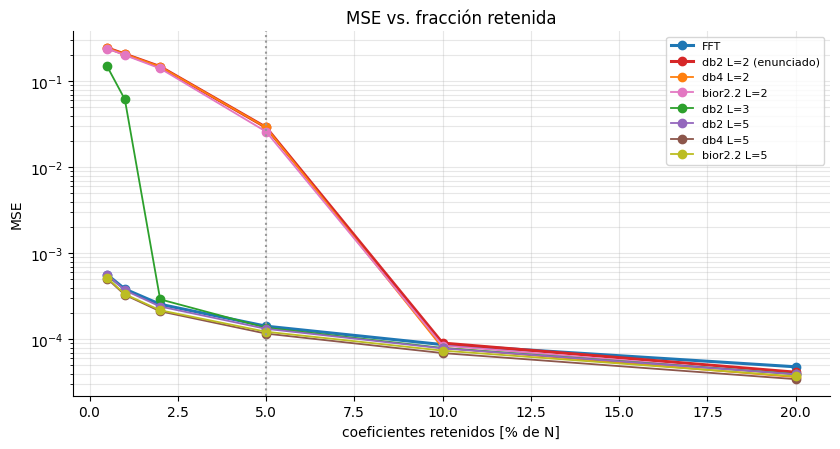

Tamaño de la banda de aproximación como fracción de N: {'L=2': '6.25 %', 'L=3': '1.56 %', 'L=5': '0.10 %'}


In [28]:
def rec_fft_top(imagen, frac):
    Fq = fft2(imagen); E = np.abs(Fq)**2; M = int(frac * imagen.size)
    thr = np.partition(E.ravel(), -M)[-M]
    keep = E >= thr; ky, kx = np.nonzero(keep); keep[(-ky) % Hd, (-kx) % Wd] = True       # simetría hermítica
    return np.real(ifft2(np.where(keep, Fq, 0))), int(keep.sum())

def rec_dwt_top(imagen, frac, wavelet, nivel):
    arr, sl = pywt.coeffs_to_array(pywt.wavedec2(imagen, wavelet, level=nivel, mode="periodization"))
    M = int(frac * imagen.size); thr = np.partition(np.abs(arr).ravel(), -M)[-M]
    arr_c = np.where(np.abs(arr) >= thr, arr, 0)
    return pywt.waverec2(pywt.array_to_coeffs(arr_c, sl, output_format="wavedec2"), wavelet, mode="periodization"), int(np.count_nonzero(arr_c))

configs = [("FFT", None, None), ("db2 L=2 (enunciado)", "db2", 2), ("db4 L=2", "db4", 2), ("bior2.2 L=2", "bior2.2", 2),
           ("db2 L=3", "db2", 3), ("db2 L=5", "db2", 5), ("db4 L=5", "db4", 5), ("bior2.2 L=5", "bior2.2", 5)]
fracs2 = [0.005, 0.01, 0.02, 0.05, 0.10, 0.20]
mse_tab = pd.DataFrame(index=[f"{100*f:g} %" for f in fracs2], columns=[c[0] for c in configs], dtype=float)
rec5 = {}
for fr in fracs2:
    for nom, w, L in configs:
        rec, Mq = rec_fft_top(img, fr) if w is None else rec_dwt_top(img, fr, w, L)
        mse_tab.loc[f"{100*fr:g} %", nom] = np.mean((img - rec)**2)
        if abs(fr - 0.05) < 1e-9: rec5[nom] = rec
display(mse_tab.style.format("{:.3e}"))
RES["ej2_mse_tab"] = {idx: {c: float(v) for c, v in fila.items()} for idx, fila in mse_tab.iterrows()}

fig, ax = plt.subplots(figsize=(8.5, 4.6))
for (nom, w, L), col in zip(configs, ["C0", "C3", "C1", "C6", "C2", "C4", "C5", "C8"]):
    ax.semilogy([100*f for f in fracs2], mse_tab[nom], "o-", color=col, label=nom, lw=2.2 if nom.startswith(("FFT", "db2 L=2")) else 1.3)
ax.axvline(5, color="0.6", ls=":"); ax.set(xlabel="coeficientes retenidos [% de N]", ylabel="MSE", title="MSE vs. fracción retenida"); ax.legend(fontsize=8); ax.grid(alpha=.3, which="both")
plt.tight_layout(); plt.savefig(FIG / "ej2_mse_vs_fraccion.png", bbox_inches="tight"); plt.show()
print("Tamaño de la banda de aproximación como fracción de N:", {f"L={L}": f"{100/4**L:.2f} %" for L in (2, 3, 5)})

,RMS error en cielo,RMS error cerca de fuentes,RMS total,mín. reconstruido,píxeles < 0 [%]
FFT,0.0110,0.0370,0.0119,0.2321,0.0000
db2 L=2 (enunciado),0.1763,0.1782,0.1706,-0.4029,2.8543
db2 L=5,0.0113,0.0147,0.0115,0.2044,0.0000


,cA_L ocupa [% de N],retenidos que son de cA_L [%],cA_L conservada [%]
db2 L=2,6.2,100.0,80.0
bior2.2 L=2,6.2,100.0,80.0
db2 L=3,1.6,31.3,100.0
db2 L=5,0.1,2.0,100.0


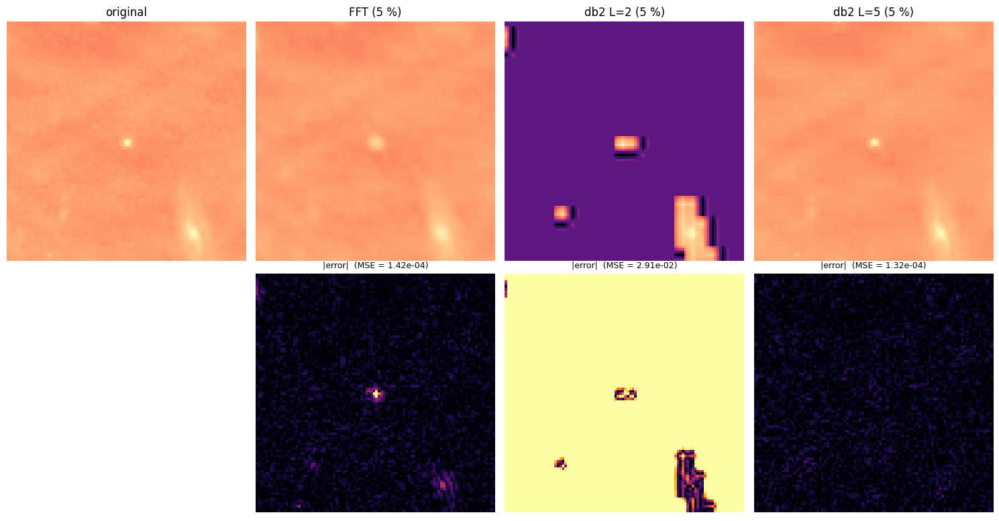

In [29]:
# ¿Dónde cae el error al 5 %? (cielo vacío / cerca de fuentes brillantes / total) y píxeles con valor negativo (físicamente imposible)
filas = {}
for nom in ["FFT", "db2 L=2 (enunciado)", "db2 L=5"]:
    e = img - rec5[nom]
    filas[nom] = {"RMS error en cielo": np.sqrt(np.mean(e[cielo]**2)), "RMS error cerca de fuentes": np.sqrt(np.mean(e[cerca]**2)),
                  "RMS total": np.sqrt(np.mean(e**2)), "mín. reconstruido": rec5[nom].min(), "píxeles < 0 [%]": 100*np.mean(rec5[nom] < 0)}
tabla_C = pd.DataFrame(filas).T; display(tabla_C.style.format("{:.4f}"))

def composicion_retenidos(imagen, frac, wavelet, nivel):
    """¿Qué parte del presupuesto de coeficientes se gasta en la banda de aproximación cA_L?"""
    arr, sl = pywt.coeffs_to_array(pywt.wavedec2(imagen, wavelet, level=nivel, mode="periodization"))
    M = int(frac * imagen.size); thr = np.partition(np.abs(arr).ravel(), -M)[-M]
    keep = np.abs(arr) >= thr; ka = keep[sl[0]]
    return dict(banda_aprox_pct_de_N=100 * ka.size / arr.size, retenidos_en_aprox_pct=100 * ka.sum() / keep.sum(), aprox_retenida_pct=100 * ka.mean())
comp = {f"{w} L={L}": composicion_retenidos(img, 0.05, w, L) for w, L in [("db2", 2), ("bior2.2", 2), ("db2", 3), ("db2", 5)]}
display(pd.DataFrame(comp).T.rename(columns={"banda_aprox_pct_de_N": "cA_L ocupa [% de N]", "retenidos_en_aprox_pct": "retenidos que son de cA_L [%]", "aprox_retenida_pct": "cA_L conservada [%]"}).style.format("{:.1f}"))
RES["ej2_composicion_5pct"] = comp
RES["ej2_tabla_C"] = {k: {c: float(v) for c, v in fila.items()} for k, fila in tabla_C.iterrows()}

# Recorte alrededor de la fuente más brillante: reconstrucciones y error absoluto al 5 %
y, x0 = fuentes[0]; ya, xa = np.clip(y-48, 0, Hd-96), np.clip(x0-48, 0, Wd-96)
fig, ax = plt.subplots(2, 4, figsize=(15, 7.8))
for c, (nom, im_) in enumerate([("original", img), ("FFT (5 %)", rec5["FFT"]), ("db2 L=2 (5 %)", rec5["db2 L=2 (enunciado)"]), ("db2 L=5 (5 %)", rec5["db2 L=5"])]):
    ax[0, c].imshow(np.arcsinh(im_[ya:ya+96, xa:xa+96] / 0.05), cmap="magma", vmin=-1.5, vmax=3.7); ax[0, c].set_title(nom); ax[0, c].axis("off")
    if c: ax[1, c].imshow(np.abs(img - im_)[ya:ya+96, xa:xa+96], cmap="inferno", vmin=0, vmax=0.2); ax[1, c].set_title(f"|error|  (MSE = {np.mean((img-im_)**2):.2e})", fontsize=9)
    ax[1, c].axis("off")
plt.tight_layout(); plt.savefig(FIG / "ej2_compresion_5pct.png", bbox_inches="tight"); plt.show()

---
## Pregunta A — ¿qué método conserva con mayor fidelidad la forma y la posición de las fuentes sin alterar el fondo oscuro?

**Respuesta corta.** **Ninguno gana en todo**; depende de qué se entienda por "fidelidad". La **2D-FFT con pasa-altas gaussiano** conserva mejor la **forma** y la **posición** de las fuentes; la **wavelet** deja un **fondo mucho más limpio** pero deforma más las fuentes. Medido sobre 37 fuentes compactas y aisladas (detectadas sobre la imagen residual, por ser el fondo estructurado):

| | Wavelet db2 L=2, umbral suave | FFT gaussiano ($f_c=1/8$) | FFT ideal |
|---|---|---|---|
| Posición del máximo a ≤ 1 px | 92% | 100% | 100% |
| Correlación de forma (recorte 11×11) | 0.60 | 0.88 | 0.81 |
| Retención del pico | 0.47 | 0.51 | 0.59 |
| RMS en cielo vacío | 0.0050 | 0.0112 | 0.0132 |

* **Posición:** ambos métodos localizan bien las fuentes; el filtro gaussiano algo mejor (100% frente a 92%). Una posible causa de la menor precisión de la wavelet es que la DWT trabaja en una rejilla diádica (cada 4 px con L = 2).
* **Forma:** la FFT es claramente mejor (correlación 0.88 frente a 0.60). En los recortes y perfiles se ve que la wavelet conserva en media el 47% del pico (la FFT gaussiana, el 51%) y lo deja "pixelado".
* **Fondo oscuro:** aquí gana la wavelet, por un factor ≈ 2.2: su RMS en cielo vacío es el 4 % de la dispersión robusta (MAD) de la imagen original ($\hat\sigma$ = 0.1205; en un campo vacío es el ruido del fondo, en una imagen con nebulosa incluye su estructura) frente al 9 % con la FFT. El ruido del fondo tiene energía en todas las frecuencias, de modo que un pasa-altas sólo elimina su parte de baja frecuencia y deja casi todo lo demás; la umbralización suave, en cambio, pone a cero todos los coeficientes menores que $\lambda=$ 0.0314 (5.5 $\hat\sigma_w$, con $\hat\sigma_w=$ 0.0057 estimada con MAD en $cD_1$), y sólo sobrevive el 3.96 % de los coeficientes de detalle.

**¿Es un artefacto de los parámetros?** **Sólo en parte.** La conclusión sobre la **forma** no depende de ellos: para $\lambda\in[2,\,5.5]\,\hat\sigma$ la wavelet queda siempre con correlación ≤ 0.62, mientras que el filtro gaussiano con $f_c\in[1/16,\,1/4]$ obtiene de 0.75 a 0.98. La del **cielo sí depende**: la wavelet queda entre 0.0050 y 0.0081 de RMS y el gaussiano entre 0.0069 (con $f_c=1/4$) y 0.0162 (con $f_c=1/16$); con $f_c=1/4$ el filtro gaussiano deja un cielo comparable que la wavelet, a cambio de conservar menos el pico (0.22) y de localizar peor (100%). Hay, pues, un compromiso en la FFT: bajando $f_c$ mejora la forma pero deja más ruido en el cielo, y la ventaja de la wavelet en el fondo desaparece si se sube $f_c$.

**Por qué la wavelet deforma más las fuentes.** (i) El umbral suave **resta $\lambda$ a cada coeficiente que sobrevive**, lo que encoge sistemáticamente las fuentes (sesgo conocido de la umbralización suave): con umbral duro la retención del pico sube de 0.47 a 0.55 y la correlación de 0.60 a 0.61 (a costa de más ruido en el cielo: 0.0089). Aquí el cambio es pequeño, así que el sesgo del umbral suave **no** es la causa principal de la deformación. Ambos métodos eliminan además la baja frecuencia de la propia fuente ($cA_2=0$ en la wavelet, $H(0)=0$ en la FFT). (ii) La DWT **no es invariante a traslaciones** (Experimento 1b): la misma estrella queda con entre 37% y 80% de su pico según caiga respecto a la rejilla de 4 px, mientras que el filtro lineal da siempre 69%.



**Veredicto.** Para **detectar** fuentes (cielo limpio y posición correcta en el 92% de los casos) la wavelet es preferible; para **medir forma y flujo** de las fuentes, el pasa-altas gaussiano. *Limitaciones:* imagen normalizada por percentiles (0.5–99.95 %): los MSE son relativos, no están en unidades de flujo, fuentes de referencia seleccionadas sobre la propia imagen original y una sola imagen.


---
## Pregunta B — ¿por qué la 2D-FFT produce *ringing* (Gibbs) y las wavelets no? Explicación matemática

**1 · El filtrado en frecuencia es una convolución.** Por el teorema de convolución,
$$f_{fft}=\mathcal F^{-1}\{F\cdot H\}=h*f,\qquad h=\mathcal F^{-1}\{H\}.$$
Cada fuente puntual se sustituye por una copia de la **respuesta al impulso** $h$. Si $H$ tiene una discontinuidad, $h$ no tiene soporte compacto y oscila.

**2 · Filtro ideal (corte abrupto): Gibbs.** Para $H=1-\mathbf 1_{\{D\le D_0\}}$ se tiene $h=\delta-h_{LP}$ con el núcleo "jinc"
$$h_{LP}(r)=D_0\,\frac{J_1(2\pi D_0 r)}{r}\;\sim\; r^{-3/2}\cos\!\left(2\pi D_0 r-\tfrac{3\pi}{4}\right),\quad r\to\infty,$$
que oscila con periodo $1/D_0\approx$ 9.4 px y decae sólo como $r^{-3/2}$: el artefacto se extiende a **toda la imagen**. La causa es que una discontinuidad en el dominio de Fourier equivale a un decaimiento lento en el espacio. Es el fenómeno de Gibbs (por dualidad, el mismo que aparece al truncar la serie de Fourier de una discontinuidad en el espacio): la serie de Fourier truncada de una discontinuidad de salto 1 rebasa el valor en $\tfrac1\pi\mathrm{Si}(\pi)-\tfrac12\approx$ 8.95 % **sin importar cuántos términos se usen** (Experimento 2: 9.065 % con 11 armónicos y 8.949 % con 1001). Una fuente brillante es un salto/impulso cuyo espectro es de banda ancha; al truncar o filtrar bruscamente ese espectro se pierde la coherencia de fases que lo mantenía localizado.

*Medido (Experimento 1):* filtro ideal → 3 cambios de signo y un radio que contiene el 99 % de la energía de 42 px.

**3 · Matiz importante: el filtro gaussiano que pide el enunciado casi no produce Gibbs.** Para $H=1-e^{-D^2/2D_0^2}$, que es $C^\infty$ (sin discontinuidad), $h=\delta-2\pi D_0^2\,e^{-2\pi^2D_0^2r^2}$: un núcleo gaussiano de $\sigma_r=1/(2\pi D_0)\approx$ 1.5 px, sin oscilaciones largas (1 cambio de signo y radio de 99 % de energía de 4 px). El "halo" negativo que sí se observa (≈ -0.10 del pico) **no es Gibbs**: viene de que $H(0)=0$, es decir $\int h=0$, así que $h$ **debe** tener una parte negativa (el filtro quita la media local alrededor de cada fuente). La pregunta B se cumple, por tanto, para el pasa-altas ideal, y sólo en parte para el gaussiano.

**4 · Wavelets: artefactos acotados por el soporte.** La reconstrucción es $f=\sum_{j,k}c_{j,k}\,\psi_{j,k}$ con $\psi$ de soporte compacto (db2 tiene 4 coeficientes de filtro; a nivel $j$ su soporte es de $3(2^j-1)+1$ muestras, es decir, 10 px a $j=2$). Modificar o anular un coeficiente sólo puede alterar la imagen **dentro del soporte de su átomo**, así que el error no puede propagarse más allá de unos pocos píxeles; y la umbralización suave actúa coeficiente a coeficiente, sin un corte abrupto en frecuencia. *Medido:* radio del 99 % de la energía de la respuesta de la wavelet = 6 px, frente a 42 px del filtro ideal.

**5 · Pero las wavelets *no* están libres de artefactos.** Dentro de su soporte, la respuesta de la wavelet tiene un lóbulo negativo de entre -0.20 y -0.58 veces su pico (según la posición de la fuente), **mayor en términos relativos que el del filtro gaussiano** (-0.10). Causas: $cA_2=0$ también impone media cero; la DWT no es invariante a traslaciones; y db2 tiene sólo 2 momentos nulos y no es simétrica. Esos defectos se manifiestan como "bloques" (ver la compresión al 5 %). La conclusión correcta es: **las wavelets acotan *dónde* aparecen los artefactos (localidad), no su amplitud**.


---
## Pregunta C — compresión reteniendo sólo el 5 % de los coeficientes: ¿qué método garantiza menor MSE?

**Respuesta corta.** **Ninguno lo garantiza para cualquier configuración**; depende de la profundidad $L$ y de la familia. A $L=2$ (el presupuesto del 5 % es menor que la banda $cA_2$): `db2 L=2`: 205 veces el MSE de la FFT (**peor**); `db4 L=2`: 204 veces el MSE de la FFT (**peor**); `bior2.2 L=2`: 183 veces el MSE de la FFT (**peor**). Con $L\ge3$: `db2 L=3`: prácticamente igual a la FFT (cociente de MSE 0.960); `db2 L=5`: 1.07 veces menos MSE que la FFT (**mejor**); `db4 L=5`: 1.22 veces menos MSE que la FFT (**mejor**); `bior2.2 L=5`: 1.16 veces menos MSE que la FFT (**mejor**); en conjunto, las wavelets empatan o ganan por poco (la FFT sigue siendo competitiva). MSE al 5 % (menor es mejor):

| FFT | db2 L=2 *(enunciado)* | db4 L=2 | bior2.2 L=2 | db2 L=3 | db2 L=5 | db4 L=5 | bior2.2 L=5 |
|---|---|---|---|---|---|---|---|
| 1.42e-04 | 2.91e-02 | 2.91e-02 | 2.60e-02 | 1.36e-04 | 1.32e-04 | 1.17e-04 | 1.23e-04 |

* Con db2 a $L=2$ (la configuración usada en la Parte 4): 205 veces el MSE de la FFT (**peor**); con `bior2.2` a $L=2$: 183 veces el MSE de la FFT (**peor**).
* Con $L=3$ (db2): prácticamente igual a la FFT (cociente de MSE 0.960); con $L=5$ (db2): 1.07 veces menos MSE que la FFT (**mejor**); con $L=5$ y `bior2.2`: 1.16 veces menos MSE que la FFT (**mejor**). Con el 10 % de coeficientes, a $L=2$ ganan a la FFT (8.68e-05) sólo `db4 L=2`, `bior2.2 L=2`.

**Por qué (el criterio).** Ambas transformadas son (casi) ortonormales, así que por Parseval $\mathrm{MSE}=\tfrac1n\sum(\text{coeficientes descartados})^2$, y la mejor aproximación con $M$ términos consiste en conservar los $M$ coeficientes de mayor módulo. Gana, por tanto, la base en la que la imagen es **más dispersa** (energía concentrada en menos coeficientes). Una imagen de campo profundo es un conjunto de **estructuras localizadas** (fuentes compactas) sobre un fondo suave más ruido: una base global como la de Fourier necesita muchas frecuencias coherentes para localizar cada fuente, mientras que una wavelet de soporte compacto la describe con pocos coeficientes por escala.

**Por qué a $L=2$ y 5 % no se aprecia la ventaja.** La banda de aproximación $cA_2$ tiene 262144 coeficientes (el 6.25 % de $N$), más que todo el presupuesto de 209715 coeficientes (5 %). Como los coeficientes de aproximación son los de mayor módulo, el 100 % de lo retenido es de $cA_2$ y queda sólo ≈ 0 % para los detalles que describen las fuentes; y ni siquiera la propia banda $cA_2$ se conserva entera (sólo el 80 %). Resultado: reconstrucción con "bloques" oscuros y 2.9 % de píxeles negativos (imposibles físicamente), frente a 0.0 % con la FFT. Con $L=5$ la aproximación ocupa sólo el 0.10 % de $N$ y casi todo el presupuesto se dedica a detalles. El error de db2 a $L=5$ (1.32e-04) es sólo el 0.91 % de la varianza robusta de la imagen ($\hat\sigma^2\approx$ 1.5e-02) y 4.1 veces la varianza del ruido a escala de píxel ($\hat\sigma_w^2\approx$ 3.2e-05): la imagen es muy compresible y el 5 % de los coeficientes recoge casi toda la señal; que el error siga por encima del ruido a escala de píxel indica que queda algo de estructura sin representar (no demostrado aquí).

**Conclusión de C.** Para esta imagen, **una DWT con $L\ge3$ queda, al 5 %, entre 0.82 y 0.96 veces el MSE de la FFT** (la mejor, `db4 L=5`): la ventaja de las wavelets sobre la FFT es pequeña y depende de la familia y de $L$. No hay garantía general: depende de $L$, de la familia y del presupuesto. *Limitaciones:* una imagen, MSE medido sobre la imagen normalizada a [0, 1], y la selección por módulo no es la óptima para bases biortogonales (`bior2.2`).


---
# Ejercicio 3 · Mapa mental sistémico
Mapa conceptual jerárquico (raíz → 5 nodos temáticos → subconceptos) con **8 enlaces explícitos y etiquetados entre los cinco nodos** (flechas discontinuas). Se dibuja con *matplotlib* con diseño manual; el motor de disposición automática de Mermaid escalonaba los cinco nodos al ligarlos entre sí y perdía la jerarquía.

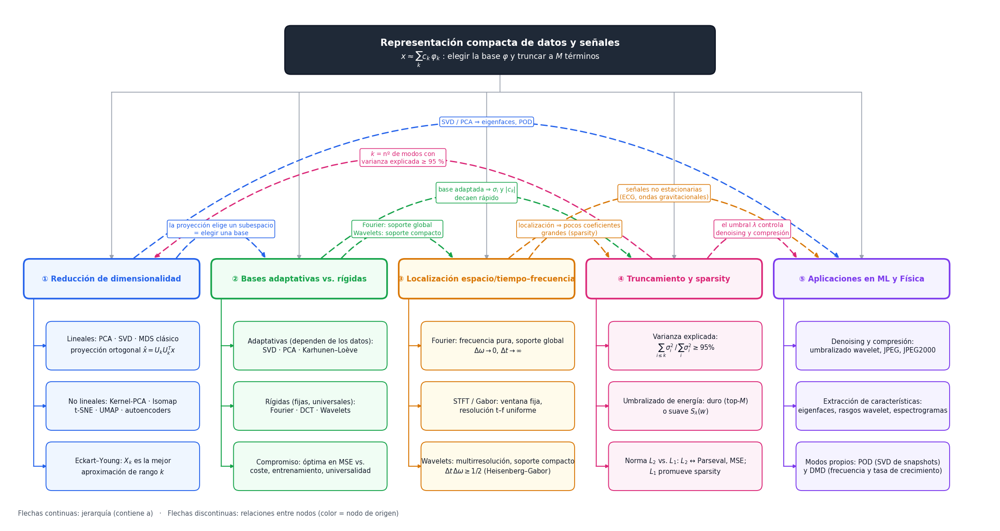

In [30]:
"""Mapa mental sistémico (Ejercicio 3): jerarquía raíz -> 5 nodos -> 3 subconceptos + enlaces cruzados etiquetados."""
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib.path import Path as MplPath

NODOS = [
    dict(id=1, color="#2563eb", fondo="#eff6ff", titulo="① Reducción de dimensionalidad",
         hijos=["Lineales: PCA · SVD · MDS clásico\nproyección ortogonal $\\hat{x}=U_kU_k^{T}x$",
                "No lineales: Kernel-PCA · Isomap\nt-SNE · UMAP · autoencoders",
                "Eckart–Young: $X_k$ es la mejor\naproximación de rango $k$"]),
    dict(id=2, color="#16a34a", fondo="#f0fdf4", titulo="② Bases adaptativas vs. rígidas",
         hijos=["Adaptativas (dependen de los datos):\nSVD · PCA · Karhunen–Loève",
                "Rígidas (fijas, universales):\nFourier · DCT · Wavelets",
                "Compromiso: óptima en MSE vs.\ncoste, entrenamiento, universalidad"]),
    dict(id=3, color="#d97706", fondo="#fffbeb", titulo="③ Localización espacio/tiempo–frecuencia",
         hijos=["Fourier: frecuencia pura, soporte global\n$\\Delta\\omega\\to 0$, $\\Delta t\\to\\infty$",
                "STFT / Gabor: ventana fija,\nresolución t–f uniforme",
                "Wavelets: multirresolución, soporte compacto\n$\\Delta t\\,\\Delta\\omega\\geq 1/2$ (Heisenberg–Gabor)"]),
    dict(id=4, color="#db2777", fondo="#fdf2f8", titulo="④ Truncamiento y sparsity",
         hijos=["Varianza explicada:\n$\\sum_{i\\leq k}\\sigma_i^2\\,/\\,\\sum_i\\sigma_i^2\\geq 95\\%$",
                "Umbralizado de energía: duro (top-$M$)\no suave $S_\\lambda(w)$",
                "Norma $L_2$ vs. $L_1$: $L_2$ ↔ Parseval, MSE;\n$L_1$ promueve sparsity"]),
    dict(id=5, color="#7c3aed", fondo="#f5f3ff", titulo="⑤ Aplicaciones en ML y Física",
         hijos=["Denoising y compresión:\numbralizado wavelet, JPEG, JPEG2000",
                "Extracción de características:\neigenfaces, rasgos wavelet, espectrogramas",
                "Modos propios: POD (SVD de snapshots)\ny DMD (frecuencia y tasa de crecimiento)"]),
]

# (origen, destino, altura del arco, etiqueta)
ENLACES = [
    (1, 2, 0.65, "la proyección elige un subespacio\n= elegir una base"),
    (2, 3, 0.65, "Fourier: soporte global\nWavelets: soporte compacto"),
    (3, 4, 0.65, "localización ⇒ pocos coeficientes\ngrandes (sparsity)"),
    (4, 5, 0.65, "el umbral $\\lambda$ controla\ndenoising y compresión"),
    (2, 4, 1.45, "base adaptada ⇒ $\\sigma_i$ y $|c_k|$\ndecaen rápido"),
    (3, 5, 1.45, "señales no estacionarias\n(ECG, ondas gravitacionales)"),
    (4, 1, 2.25, "$k$ = nº de modos con\nvarianza explicada ≥ 95 %"),
    (1, 5, 3.05, "SVD / PCA ⇒ eigenfaces, POD"),
]


def dibujar_mapa(ruta_base=None, mostrar=False):
    W, Hh = 22.2, 11.7
    fig, ax = plt.subplots(figsize=(W, Hh))
    ax.set_xlim(0, W); ax.set_ylim(0, Hh); ax.set_aspect("equal"); ax.axis("off")

    ancho_main, alto_main = 3.9, 0.85
    paso = 4.2
    cx = {n["id"]: 2.4 + paso*(n["id"]-1) for n in NODOS}
    y_main = 5.55                      # centro de la fila de nodos principales
    y_top = y_main + alto_main/2       # borde superior
    y_bus = y_top + 3.75               # barra horizontal desde la raíz
    y_root = y_bus + 0.95

    def caja(x, y, w, h, fc, ec, lw=1.6, z=3):
        p = FancyBboxPatch((x-w/2, y-h/2), w, h, boxstyle="round,pad=0.02,rounding_size=0.13",
                           fc=fc, ec=ec, lw=lw, zorder=z)
        ax.add_patch(p)

    # raíz
    caja(W/2, y_root, 9.6, 1.05, "#1f2937", "#111827", lw=2)
    ax.text(W/2, y_root+0.17, "Representación compacta de datos y señales", color="white",
            ha="center", va="center", fontsize=15, fontweight="bold", zorder=4)
    ax.text(W/2, y_root-0.2, "$x\\approx\\sum_k c_k\\,\\varphi_k$ : elegir la base $\\varphi$ y truncar a $M$ términos",
            color="white", ha="center", va="center", fontsize=12.5, zorder=4)

    # barra raíz -> nodos principales
    ax.plot([W/2, W/2], [y_root-0.525, y_bus], color="#9ca3af", lw=1.3, zorder=1)
    ax.plot([cx[1], cx[5]], [y_bus, y_bus], color="#9ca3af", lw=1.3, zorder=1)
    for n in NODOS:
        ax.add_patch(FancyArrowPatch((cx[n["id"]], y_bus), (cx[n["id"]], y_top), arrowstyle="-|>",
                                     mutation_scale=14, color="#9ca3af", lw=1.3, zorder=1, shrinkA=0, shrinkB=0))

    # nodos principales + hijos
    alto_hijo, sep_hijo = 1.05, 0.3
    ancho_hijo = 3.4
    for n in NODOS:
        x = cx[n["id"]]
        caja(x, y_main, ancho_main, alto_main, n["fondo"], n["color"], lw=2.6)
        ax.text(x, y_main, n["titulo"], ha="center", va="center", fontsize=12.2, fontweight="bold",
                color=n["color"], zorder=4)
        x_tronco = x - ancho_main/2 + 0.2
        y_prev = y_main - alto_main/2
        y_fin = None
        for k, h in enumerate(n["hijos"]):
            yc = y_main - alto_main/2 - 0.55 - alto_hijo/2 - k*(alto_hijo+sep_hijo)
            xl = x + ancho_main/2 - ancho_hijo/2
            caja(xl, yc, ancho_hijo, alto_hijo, n["fondo"], n["color"], lw=1.4)
            ax.text(xl, yc, h, ha="center", va="center", fontsize=10.6, color="#111827", zorder=4, linespacing=1.35)
            ax.add_patch(FancyArrowPatch((x_tronco, yc), (xl-ancho_hijo/2, yc), arrowstyle="-|>",
                                         mutation_scale=11, color=n["color"], lw=1.5, zorder=2, shrinkA=0, shrinkB=0))
            y_fin = yc
        ax.plot([x_tronco, x_tronco], [y_main-alto_main/2, y_fin], color=n["color"], lw=1.5, zorder=2)

    # enlaces cruzados: puntos de anclaje en el borde superior con anidamiento sin cruces
    color = {n["id"]: n["color"] for n in NODOS}
    anclas = {}
    for i in cx:
        izq, der = [], []
        for e, (a, b, h, _) in enumerate(ENLACES):
            otro = b if a == i else a if b == i else None
            if otro is None: continue
            (izq if otro < i else der).append((abs(otro-i), e))
        izq.sort()                      # más cercano primero  -> más a la izquierda
        der.sort(reverse=True)          # más lejano primero   -> más cerca del centro
        slots_izq = [-1.45, -0.95, -0.5][: len(izq)] if len(izq) > 1 else [-0.75]
        slots_der = [0.5, 0.95, 1.45][: len(der)] if len(der) > 1 else [0.75]
        # orden izquierda->derecha: cercanos izq (más a la izq) ... lejanos izq (cerca del centro)
        izq_pos = sorted(slots_izq)
        der_pos = sorted(slots_der)
        for (_, e), s in zip(izq, izq_pos): anclas[(i, e)] = cx[i] + s
        for (_, e), s in zip(der, der_pos): anclas[(i, e)] = cx[i] + s

    for e, (a, b, h, txt) in enumerate(ENLACES):
        x0, x1 = anclas[(a, e)], anclas[(b, e)]
        y0 = y_top + 0.04
        verts = [(x0, y0), ((x0+x1)/2, y0+2*h), (x1, y0)]
        path = MplPath(verts, [MplPath.MOVETO, MplPath.CURVE3, MplPath.CURVE3])
        ax.add_patch(FancyArrowPatch(path=path, arrowstyle="-|>", mutation_scale=15, lw=2.0,
                                     linestyle=(0, (5, 3)), color=color[a], zorder=5, shrinkA=0, shrinkB=0))
        xm, ym = (x0+x1)/2, y0+h
        ax.text(xm, ym, txt, ha="center", va="center", fontsize=9.8, color=color[a], zorder=6, linespacing=1.3,
                bbox=dict(boxstyle="round,pad=0.28", fc="white", ec=color[a], lw=1.1))

    ax.text(0.3, 0.3, "Flechas continuas: jerarquía (contiene a)   ·   Flechas discontinuas: relaciones entre nodos (color = nodo de origen)",
            fontsize=10.5, color="#4b5563", ha="left", va="center")
    fig.tight_layout(pad=0.3)
    if ruta_base:
        for ext in ("png", "svg", "pdf"):
            fig.savefig(f"{ruta_base}.{ext}", dpi=150 if ext == "png" else None, facecolor="white")
    if mostrar:
        plt.show()
    return fig


fig_mapa = dibujar_mapa(FIG / "mapa_mental", mostrar=True)


**Enlaces entre los nodos (lectura del mapa).**

| Enlace | Relación | Justificación |
|---|---|---|
| ① → ② | la proyección elige un subespacio = elegir una base | Proyectar ortogonalmente sobre un subespacio de dimensión $k$ equivale a fijar una base ortonormal y quedarse con $k$ coordenadas; la base puede aprenderse de los datos (SVD/PCA) o ser fija (Fourier, DCT, wavelets). |
| ② → ③ | soporte global vs. compacto | Entre las bases fijas, Fourier tiene soporte global (frecuencia exacta, sin información temporal) y las wavelets tienen soporte compacto (compromiso tiempo–frecuencia, multirresolución). |
| ③ → ④ | localización ⇒ sparsity | Si la base está localizada como la señal (transitorios, bordes, fuentes puntuales), pocos coeficientes concentran casi toda la energía y el truncamiento es eficaz. |
| ② → ④ | base adaptada ⇒ decaimiento rápido | La base adaptada (KLT/SVD) concentra la energía de forma óptima: $\sigma_i$ y $\lvert c_k\rvert$ decaen lo más rápido posible (Eckart–Young). |
| ④ → ① | $k$ por varianza explicada | El número de componentes $k$ se fija con la varianza explicada acumulada (p. ej. ≥ 95 %), cerrando el ciclo de la reducción de dimensionalidad. |
| ④ → ⑤ | el umbral $\lambda$ | El umbral (duro/suave) decide cuánto ruido se elimina (denoising) y cuánto se comprime; con $L_1$ se promueve sparsity (el umbral suave es el operador proximal de $\lambda\lVert\cdot\rVert_1$). |
| ① → ⑤ | SVD/PCA ⇒ eigenfaces, POD | La SVD/PCA da las características (eigenfaces) y los modos POD; DMD añade dinámica sobre la SVD. |
| ③ → ⑤ | señales no estacionarias | La localización tiempo–frecuencia es la que permite analizar y comprimir señales no estacionarias (ECG, ondas gravitacionales, espectros) e imágenes. |

---
## Conclusiones generales

* **Elegir la base es elegir qué es "pocos coeficientes".** Con bases ortonormales, el MSE de una compresión es la energía descartada (Parseval); gana la base en la que la señal es más *sparse*. Fourier lo es para componentes estacionarias; las wavelets, para estructuras localizadas (QRS, fuentes puntuales).
* **El MSE no basta.** En el Ejercicio 1 ambos métodos tienen el mismo MSE al 95 % de energía y, aun así, difieren en el número de coeficientes (515 frente a 289) y en cómo tratan los transitorios.
* **"Las wavelets son mejores" depende de la tarea y de los parámetros.** En el Ejercicio 2 la wavelet db2 (L = 2, $cA_2=0$) deja el cielo mucho más limpio (RMS 0.0050 frente a 0.0112 con la FFT), pero deforma más las fuentes (correlación de forma 0.60 frente a 0.88); y en la compresión al 5 % sólo supera a la FFT con L ≥ 3 o con `bior2.2`.
* **Limitaciones comunes:** una sola señal y una sola imagen por ejercicio; imagen normalizada por percentiles (0.5–99.95 %): los MSE son relativos, no están en unidades de flujo; fuentes de referencia seleccionadas sobre la propia imagen original.


---
### Referencias
* Moody, G. B. y Mark, R. G. (2001). *The impact of the MIT-BIH Arrhythmia Database*. IEEE Eng. in Medicine and Biology 20(3), 45–50. · Goldberger, A. L. et al. (2000). *PhysioBank, PhysioToolkit, and PhysioNet*. Circulation 101(23), e215–e220.
* Mallat, S. (2009). *A Wavelet Tour of Signal Processing* (3.ª ed.). Academic Press.
* Brunton, S. L. y Kutz, J. N. (2019). *Data-Driven Science and Engineering*. Cambridge University Press.
* Donoho, D. L. y Johnstone, I. M. (1994). *Ideal spatial adaptation by wavelet shrinkage*. Biometrika 81(3), 425–455.
* Material del curso: *Overview on the Fourier Analysis* (A. Argüelles y C. Galíndez, Quantum Optics Group) y *2D transforms and image processing*.

In [31]:
Path("resultados.json").write_text(json.dumps(RES, indent=1, ensure_ascii=False, default=float), encoding="utf-8")   # UTF-8 explícito (Windows usa cp1252 por defecto)
print("Resultados guardados en resultados.json:", ", ".join(sorted(k.split("_")[0] for k in RES)) and f"{len(RES)} entradas")

Resultados guardados en resultados.json: 37 entradas
